In [3]:
'''
Exploratory Data Analysis 2 SWI - CL + SC, ALL

By Anita T

October 13 2023
'''

'\nExploratory Data Analysis 2 SWI - CL + SC, ALL\n\nBy Anita T\n\nOctober 13 2023\n'

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
import seaborn as sns
from scipy import stats
from scipy.stats import norm

In [2]:
Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()

DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID','Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number','Well Tag Number','LONGITUDE','LATITUTE']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

Datat['FD'] = Datat['PRECIPITATION']-Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP']-Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP']-Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'
    
Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
#one_hot_df = pd.get_dummies(Datat['Aquifer Group'], prefix='Aquifer') #Uncomment both for regression, etc
#Datat = pd.concat([Datat, one_hot_df], axis=1)
Datat = Datat.dropna()
Datawithtime = Datat.copy()
DropDF2 = ['Aquifer Subtype', 'DATE', 'OBSWELL', 'year_month', 'Precip_Climatology',
       'Tn_Climatology', 'Tx_Climatology',]
Datat = Datat.drop(DropDF2, axis=1, errors='ignore')

In [3]:
'''
pH_values = Datat['pH'].values
median_pH = np.median(pH_values)
mad_pH = np.median(np.abs(pH_values - median_pH))

print("Unique pH values:", np.unique(pH_values))
print("Median Absolute Deviation of pH:", mad_pH)

'''

'\npH_values = Datat[\'pH\'].values\nmedian_pH = np.median(pH_values)\nmad_pH = np.median(np.abs(pH_values - median_pH))\n\nprint("Unique pH values:", np.unique(pH_values))\nprint("Median Absolute Deviation of pH:", mad_pH)\n\n'

In [4]:
'''
SWI ALL Analysis 
'''
DataAll = Datat[(Datat['Chlrid:D'] > 150) &(Datat['Specific Conductance'] > 1000) & (Datat['Residue Filterable 1.0u'] > 750)]
DataAll.shape

(31, 24)

In [5]:
filtered_dfAs = DataAll[(DataAll['As-T'] >= 0.01)]
filtered_dfMn = DataAll[(DataAll['Mn-T'] >= 0.12)]
filtered_dfPb = DataAll[(DataAll['Pb-T'] >= 0.005)]
filtered_dfU = DataAll[(DataAll['U--T'] >= 0.02)]

print("As samples above CDW limits: ", len(filtered_dfAs))
print("Mn samples above CDW limits: ", len(filtered_dfMn))
print("Pb samples above CDW limits: ", len(filtered_dfPb))
print("U samples above CDW limits: ", len(filtered_dfU))

As samples above CDW limits:  2
Mn samples above CDW limits:  10
Pb samples above CDW limits:  9
U samples above CDW limits:  0


In [14]:
DataCL = Datat[(Datat['Chlrid:D'] > 150)]
DataCL.shape

(45, 24)

In [16]:
filtered_dfAs = DataCL[(DataCL['As-T'] >= 0.01)]
filtered_dfMn = DataCL[(DataCL['Mn-T'] >= 0.12)]
filtered_dfPb = DataCL[(DataCL['Pb-T'] >= 0.005)]
filtered_dfU = DataCL[(DataCL['U--T'] >= 0.02)]
filtered_dSC = DataCL[(DataCL['Specific Conductance'] >= 1000)]
filtered_dCl = DataCL[(DataCL['Residue Filterable 1.0u'] >= 750)]



print("As samples above CDW limits: ", len(filtered_dfAs))
print("Mn samples above CDW limits: ", len(filtered_dfMn))
print("Pb samples above CDW limits: ", len(filtered_dfPb))
print("U samples above CDW limits: ", len(filtered_dfU))
print("Specific Conductance >= 1000: ", len(filtered_dSC))
print("Residue Filterable 1.0u >= 750: ", len(filtered_dCl))

As samples above CDW limits:  2
Mn samples above CDW limits:  13
Pb samples above CDW limits:  13
U samples above CDW limits:  0
Specific Conductance >= 1000:  38
Residue Filterable 1.0u >= 750:  31


In [17]:
DataSC= Datat[(Datat['Specific Conductance'] > 1000)]
DataSC.shape

(98, 24)

In [18]:
filtered_dfAs = DataSC[(DataSC['As-T'] >= 0.01)]
filtered_dfMn = DataSC[(DataSC['Mn-T'] >= 0.12)]
filtered_dfPb = DataSC[(DataSC['Pb-T'] >= 0.005)]
filtered_dfU = DataSC[(DataSC['U--T'] >= 0.02)]
filtered_dSC = DataSCTDS[(DataSCTDS['Chlrid:D'] >= 150)]
filtered_dCl = DataSC[(DataSC['Residue Filterable 1.0u'] >= 750)]



print("As samples above CDW limits: ", len(filtered_dfAs))
print("Mn samples above CDW limits: ", len(filtered_dfMn))
print("Pb samples above CDW limits: ", len(filtered_dfPb))
print("U samples above CDW limits: ", len(filtered_dfU))
print("Chloride >= 150: ", len(filtered_dSC))
print("Residue Filterable 1.0u >= 750: ", len(filtered_dCl))

As samples above CDW limits:  7
Mn samples above CDW limits:  38
Pb samples above CDW limits:  22
U samples above CDW limits:  0
Chloride >= 150:  32
Residue Filterable 1.0u >= 750:  70


In [7]:
DataClTDS = Datat[(Datat['Chlrid:D'] > 150) & (Datat['Residue Filterable 1.0u'] > 750)]
DataClTDS.shape

(31, 24)

In [8]:
filtered_dfAs = DataClTDS[(DataClTDS['As-T'] >= 0.01)]
filtered_dfMn = DataClTDS[(DataClTDS['Mn-T'] >= 0.12)]
filtered_dfPb = DataClTDS[(DataClTDS['Pb-T'] >= 0.005)]
filtered_dfU = DataClTDS[(DataClTDS['U--T'] >= 0.02)]
filtered_dSC = DataClTDS[(DataClTDS['Specific Conductance'] >= 1000)]


print("As samples above CDW limits: ", len(filtered_dfAs))
print("Mn samples above CDW limits: ", len(filtered_dfMn))
print("Pb samples above CDW limits: ", len(filtered_dfPb))
print("U samples above CDW limits: ", len(filtered_dfU))
print("Specific Conductance >= 1000: ", len(filtered_dSC))

As samples above CDW limits:  2
Mn samples above CDW limits:  10
Pb samples above CDW limits:  9
U samples above CDW limits:  0
Specific Conductance >= 1000:  31


In [9]:
DataSCTDS= Datat[(Datat['Specific Conductance'] > 1000) & (Datat['Residue Filterable 1.0u'] > 750)]
DataSCTDS.shape

(70, 24)

In [10]:
filtered_dfAs = DataSCTDS[(DataSCTDS['As-T'] >= 0.01)]
filtered_dfMn = DataSCTDS[(DataSCTDS['Mn-T'] >= 0.12)]
filtered_dfPb = DataSCTDS[(DataSCTDS['Pb-T'] >= 0.005)]
filtered_dfU = DataSCTDS[(DataSCTDS['U--T'] >= 0.02)]
filtered_dSC = DataSCTDS[(DataSCTDS['Chlrid:D'] >= 150)]


print("As samples above CDW limits: ", len(filtered_dfAs))
print("Mn samples above CDW limits: ", len(filtered_dfMn))
print("Pb samples above CDW limits: ", len(filtered_dfPb))
print("U samples above CDW limits: ", len(filtered_dfU))
print("Chloride >= 150: ", len(filtered_dSC))

As samples above CDW limits:  5
Mn samples above CDW limits:  26
Pb samples above CDW limits:  17
U samples above CDW limits:  0
Chloride >= 150:  32


In [13]:
DataSCCl= Datat[(Datat['Specific Conductance'] > 1000) & (Datat['Chlrid:D'] > 150)]
DataSCCl.shape

(37, 24)

In [12]:
filtered_dfAs = DataSCCl[(DataSCCl['As-T'] >= 0.01)]
filtered_dfMn = DataSCCl[(DataSCCl['Mn-T'] >= 0.12)]
filtered_dfPb = DataSCCl[(DataSCCl['Pb-T'] >= 0.005)]
filtered_dfU = DataSCCl[(DataSCCl['U--T'] >= 0.02)]
filtered_dSC = DataSCCl[(DataSCCl['Residue Filterable 1.0u'] >= 750)]


print("As samples above CDW limits: ", len(filtered_dfAs))
print("Mn samples above CDW limits: ", len(filtered_dfMn))
print("Pb samples above CDW limits: ", len(filtered_dfPb))
print("U samples above CDW limits: ", len(filtered_dfU))
print("Residue Filterable 1.0u >= 750: ", len(filtered_dSC))

As samples above CDW limits:  2
Mn samples above CDW limits:  10
Pb samples above CDW limits:  9
U samples above CDW limits:  0
Residue Filterable 1.0u >= 750:  31


In [19]:
'''
Handling Outliers

Notes:  
To prevent more outlier removal, use MAD score.  ID DataAll style.  Will not to Mahalanobis method due to complexity

Decided to use threshold score instead.  MAD scores takes away from metals being past the drinking water standard and SWI values

Source:
https://stats.stackexchange.com/questions/591853/interquartile-range-finding-more-than-10-times-outliers-than-zscore#:~:text=Yes%20%2D%20using%20the%20IQR%20method,will%20find%20lots%20of%20outliers.
https://saturncloud.io/blog/how-to-detect-and-exclude-outliers-in-a-pandas-dataframe/#:~:text=The%20IQR%20can%20be%20calculated,can%20be%20considered%20an%20outlier.
https://www.analyticsvidhya.com/blog/2021/05/detecting-and-treating-outliers-treating-the-odd-one-out/
'''

def replace_outliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        upper_threshold = Q3 + k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
        cleaned_dataset.loc[cleaned_dataset[col] > upper_threshold, col] = upper_threshold
    return cleaned_dataset

#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols1 = ['pH', 'Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP']
cleaned_dataset_array1 = replace_outliers_with_iqr(DataAll[numeric_cols1], 1.5)
DataAll[numeric_cols1] = cleaned_dataset_array1


def replace_outliers_with_threshold(dataset, threshold_multiplier=3):
    """
    Replace outliers in a dataset with the threshold value based on the Median Absolute Deviation (MAD).

    Parameters:
    - dataset: DataFrame containing the dataset.
    - threshold_multiplier: Multiple of the MAD to be used as the threshold (default: 3).

    Returns:
    - cleaned_dataset: DataFrame with outliers replaced by the threshold.
    """
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        col_values = cleaned_dataset[col].values
        median = np.median(col_values)
        mad = np.median(np.abs(col_values - median))
        lower_threshold = median - threshold_multiplier * mad
        upper_threshold = median + threshold_multiplier * mad
        high_outliers = (col_values - median) > upper_threshold
        cleaned_dataset.loc[high_outliers, col] = upper_threshold
        # Update col_values after replacing high outliers
        col_values = cleaned_dataset[col].values
        low_outliers = (col_values - median) < lower_threshold
        cleaned_dataset.loc[low_outliers, col] = lower_threshold
    return cleaned_dataset
'''
# Assume DataAll is your DataFrame
numeric_cols = [, 'FD', 'HW', 'MT']
# Call your function on just the numeric columns
cleaned_dataset_array = replace_outliers_with_threshold(DataAll[numeric_cols], threshold_multiplier=3)

# Convert the numpy array back to a DataFrame
cleaned_dataset = pd.DataFrame(cleaned_dataset_array, columns=numeric_cols, index=DataAll.index)

DataAll[numeric_cols] = cleaned_dataset
'''
DataAllpastremoval1 = DataAll.copy() #This is incase I screw up. Can be commented out.

#cleaned_dataset.to_csv('cleaned_dataset.csv')

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_33168\2633070041.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DataAll[numeric_cols1] = cleaned_dataset_array1


In [20]:
correlation_matall = DataAll.corr()
correlation_matall.to_cDataSCClsv('Stats/correlation_matSWIall.csv')
print(correlation_matall)

                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.171945 -0.115332 -0.009122   
As-T                                 0.171945  1.000000  0.358537  0.485017   
Ca-T                                -0.115332  0.358537  1.000000  0.309863   
Cd-T                                -0.009122  0.485017  0.309863  1.000000   
Chlrid:D                            -0.593946 -0.098218  0.452913  0.193521   
Fe-T                                 0.026029  0.335604 -0.009337  0.367432   
Mn-T                                -0.405926  0.115137  0.404474  0.412616   
N.Kjel:T                            -0.092661 -0.497110 -0.155274 -0.190204   
P--T                                -0.103951 -0.225682  0.030804 -0.156380   
Pb-T                                 0.018589  0.361118  0.108934  0.884927   
Residue Filterable 1.0u             -0.442618 -0.004729  0.449727  0.250404   
Specific Conductance                -0.485291 -0.037

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_33168\2898448023.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matall = DataAll.corr()


In [21]:
correlation_tauall = DataAll.corr(method='kendall')
print(correlation_tauall)
correlation_tauall.to_csv('Stats/correlation_tauSWIall.csv')

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_33168\2170462676.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_tauall = DataAll.corr(method='kendall')


                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.011168 -0.235422 -0.125810   
As-T                                 0.011168  1.000000  0.367097  0.454024   
Ca-T                                -0.235422  0.367097  1.000000  0.324211   
Cd-T                                -0.125810  0.454024  0.324211  1.000000   
Chlrid:D                            -0.474650 -0.118507  0.140541  0.263137   
Fe-T                                 0.097830  0.297406  0.032680  0.190363   
Mn-T                                -0.242690  0.226816  0.273617  0.266540   
N.Kjel:T                            -0.010799 -0.335760 -0.045455 -0.040526   
P--T                                 0.013058 -0.103755  0.000000  0.054449   
Pb-T                                -0.132042  0.408255  0.079397  0.667573   
Residue Filterable 1.0u             -0.298380 -0.029131  0.158180  0.286246   
Specific Conductance                -0.334774 -0.058

In [26]:
correlation_rhoSWlall = DataAll.corr(method='spearman')
correlation_rhoSWlall.to_csv('Stats/correlation_rhoSWlall.csv')
print(correlation_rhoSWlall)

                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.040297 -0.271911 -0.149014   
As-T                                 0.040297  1.000000  0.463813  0.548522   
Ca-T                                -0.271911  0.463813  1.000000  0.373308   
Cd-T                                -0.149014  0.548522  0.373308  1.000000   
Chlrid:D                            -0.685691 -0.131665  0.176115  0.353524   
Fe-T                                 0.138272  0.324939  0.043614  0.241388   
Mn-T                                -0.383086  0.338114  0.419544  0.384412   
N.Kjel:T                            -0.060912 -0.477472 -0.101079 -0.043077   
P--T                                -0.022918 -0.176951 -0.008887  0.059399   
Pb-T                                -0.159908  0.493130  0.105221  0.799172   
Residue Filterable 1.0u             -0.446036 -0.030971  0.200787  0.387369   
Specific Conductance                -0.496823 -0.071

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_33168\147700104.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_rhoSWlall = DataAll.corr(method='spearman')


In [27]:
correlation_matClSC = DataSCCl.corr()
correlation_matClSC.to_csv('Stats/correlation_matSWIClSC.csv')
print(correlation_matClSC)

                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.420881 -0.267208  0.020599   
As-T                                 0.420881  1.000000  0.021093  0.057115   
Ca-T                                -0.267208  0.021093  1.000000 -0.091378   
Cd-T                                 0.020599  0.057115 -0.091378  1.000000   
Chlrid:D                            -0.476690 -0.061918  0.600725 -0.080504   
Fe-T                                -0.112733 -0.049490 -0.049568  0.401141   
Mn-T                                -0.357355 -0.036428  0.232649  0.423002   
N.Kjel:T                            -0.062674 -0.228822 -0.138789 -0.181990   
P--T                                -0.045731 -0.092256  0.003813 -0.154854   
Pb-T                                 0.017452  0.122101 -0.045929  0.987672   
Residue Filterable 1.0u             -0.348676  0.004195  0.644445 -0.029410   
Specific Conductance                -0.378377 -0.012

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_33168\3929162399.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matClSC = DataSCCl.corr()


In [28]:
correlation_tauClSC = DataSCCl.corr(method='kendall')
print(correlation_tauClSC)
correlation_tauClSC.to_csv('Stats/correlation_tauSWIClSC.csv')

                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.081622 -0.185102 -0.133231   
As-T                                 0.081622  1.000000  0.393951  0.333385   
Ca-T                                -0.185102  0.393951  1.000000  0.164455   
Cd-T                                -0.133231  0.333385  0.164455  1.000000   
Chlrid:D                            -0.380738 -0.175431 -0.072180  0.332043   
Fe-T                                 0.126889  0.347555  0.146416  0.144639   
Mn-T                                -0.167043  0.224675  0.273684  0.200479   
N.Kjel:T                            -0.006042 -0.329019 -0.110189  0.023582   
P--T                                 0.060700  0.037242  0.074301  0.056857   
Pb-T                                -0.116402  0.294445  0.016835  0.679066   
Residue Filterable 1.0u             -0.155004 -0.080021 -0.033083  0.335176   
Specific Conductance                -0.215199 -0.132

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_33168\3602776139.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_tauClSC = DataSCCl.corr(method='kendall')


Datat.columns


#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols = ['pH']
cleaned_dataset_array = replace_outliers_with_iqr(Datat[numeric_cols], 1.5)


In [29]:
correlation_rhoSWISCCL = DataSCCl.corr(method='spearman')
correlation_rhoSWISCCL.to_csv('Stats/correlation_rhoSWISCCL.csv')
print(correlation_rhoSWISCCL)

                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.140053 -0.199241 -0.146962   
As-T                                 0.140053  1.000000  0.508659  0.411013   
Ca-T                                -0.199241  0.508659  1.000000  0.182289   
Cd-T                                -0.146962  0.411013  0.182289  1.000000   
Chlrid:D                            -0.577509 -0.226249 -0.104801  0.447844   
Fe-T                                 0.183953  0.405704  0.174692  0.178712   
Mn-T                                -0.270911  0.334406  0.420451  0.309784   
N.Kjel:T                            -0.039258 -0.469085 -0.194497  0.026810   
P--T                                 0.061354  0.038290  0.091076  0.077131   
Pb-T                                -0.141431  0.377266  0.023174  0.805070   
Residue Filterable 1.0u             -0.260359 -0.086978 -0.068287  0.472734   
Specific Conductance                -0.343707 -0.155

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_33168\2071505680.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_rhoSWISCCL = DataSCCl.corr(method='spearman')


In [ ]:
'''from sklearn.preprocessing import PowerTransformer

# Create a PowerTransformer object
pt = PowerTransformer(method='yeo-johnson')

# Define the column names you want to transform
cols_to_transform = ['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP']
# Apply the transformation to the specified columns
df_SWIcl[cols_to_transform] = pt.fit_transform(df_SWIcl[cols_to_transform])'''

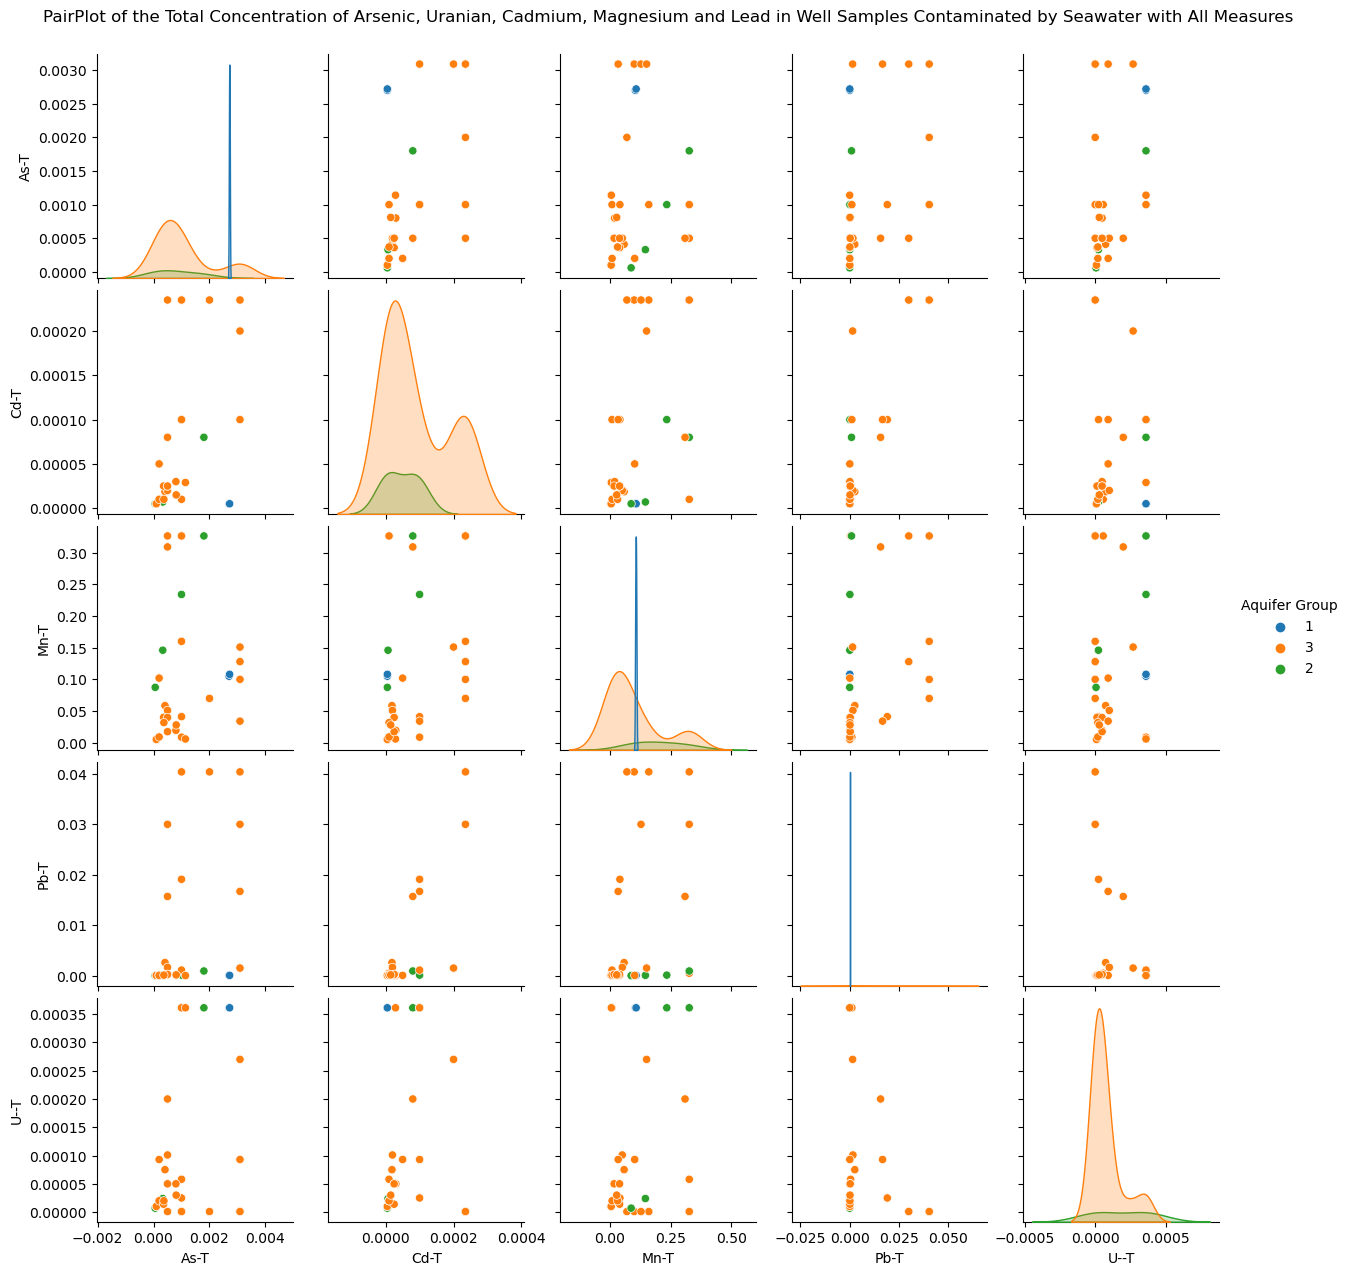

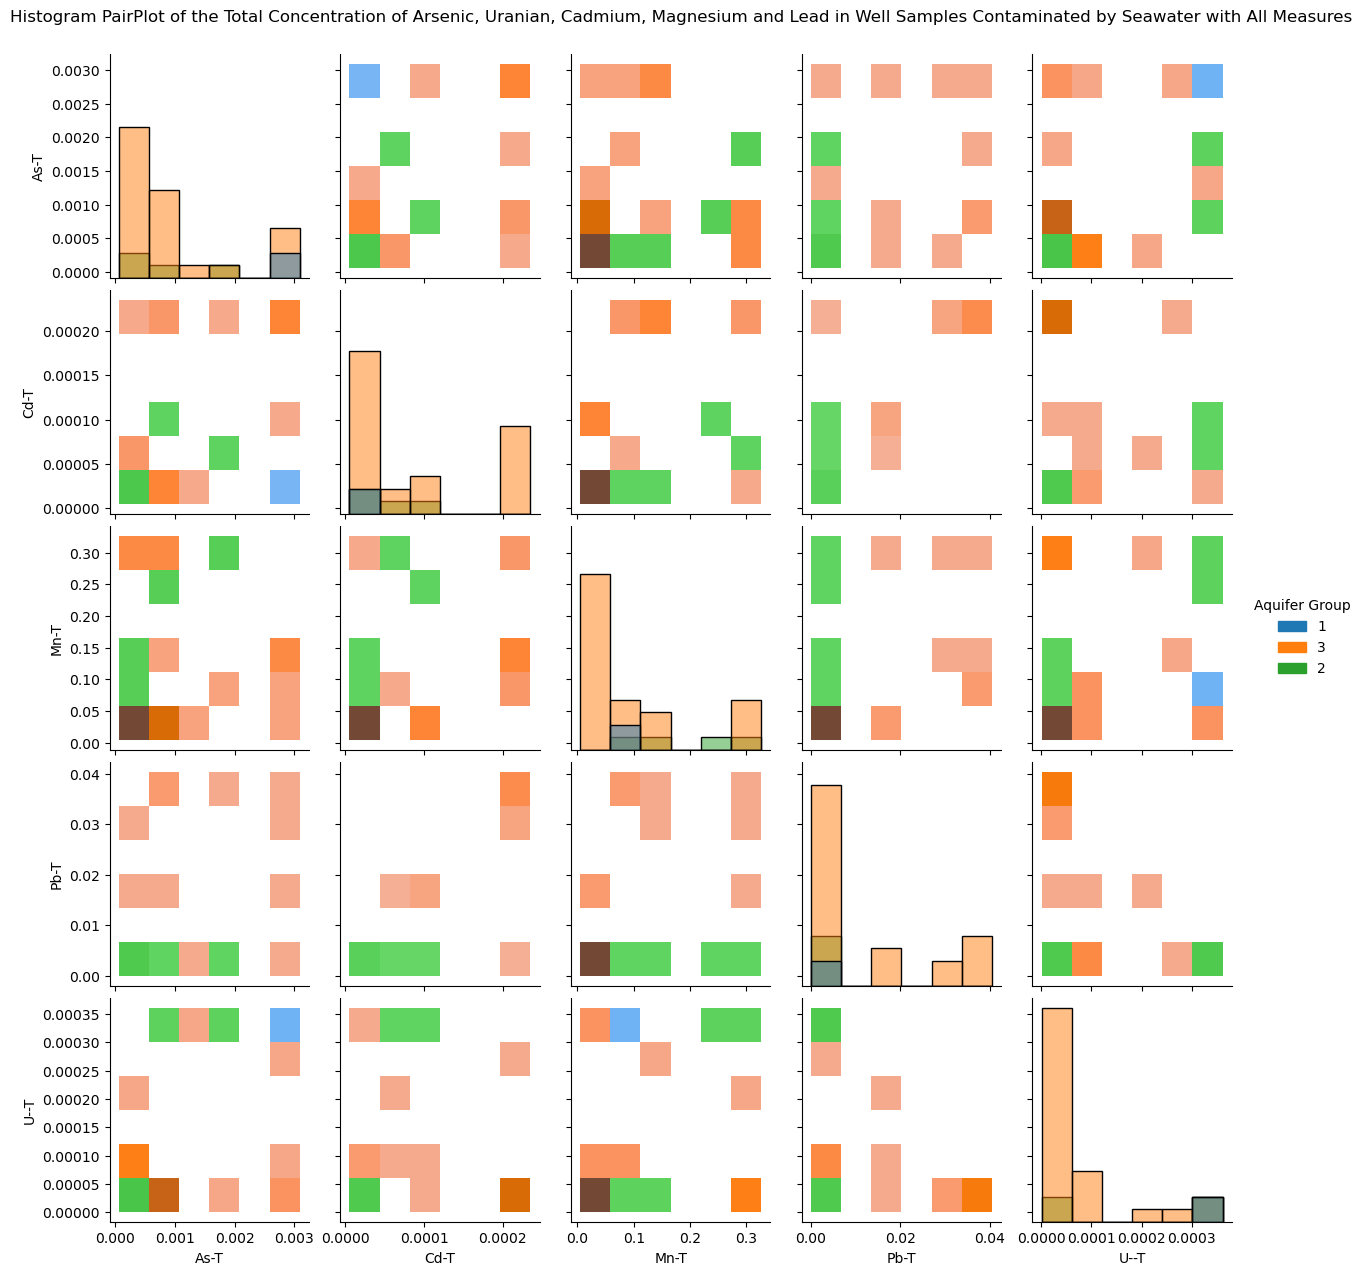

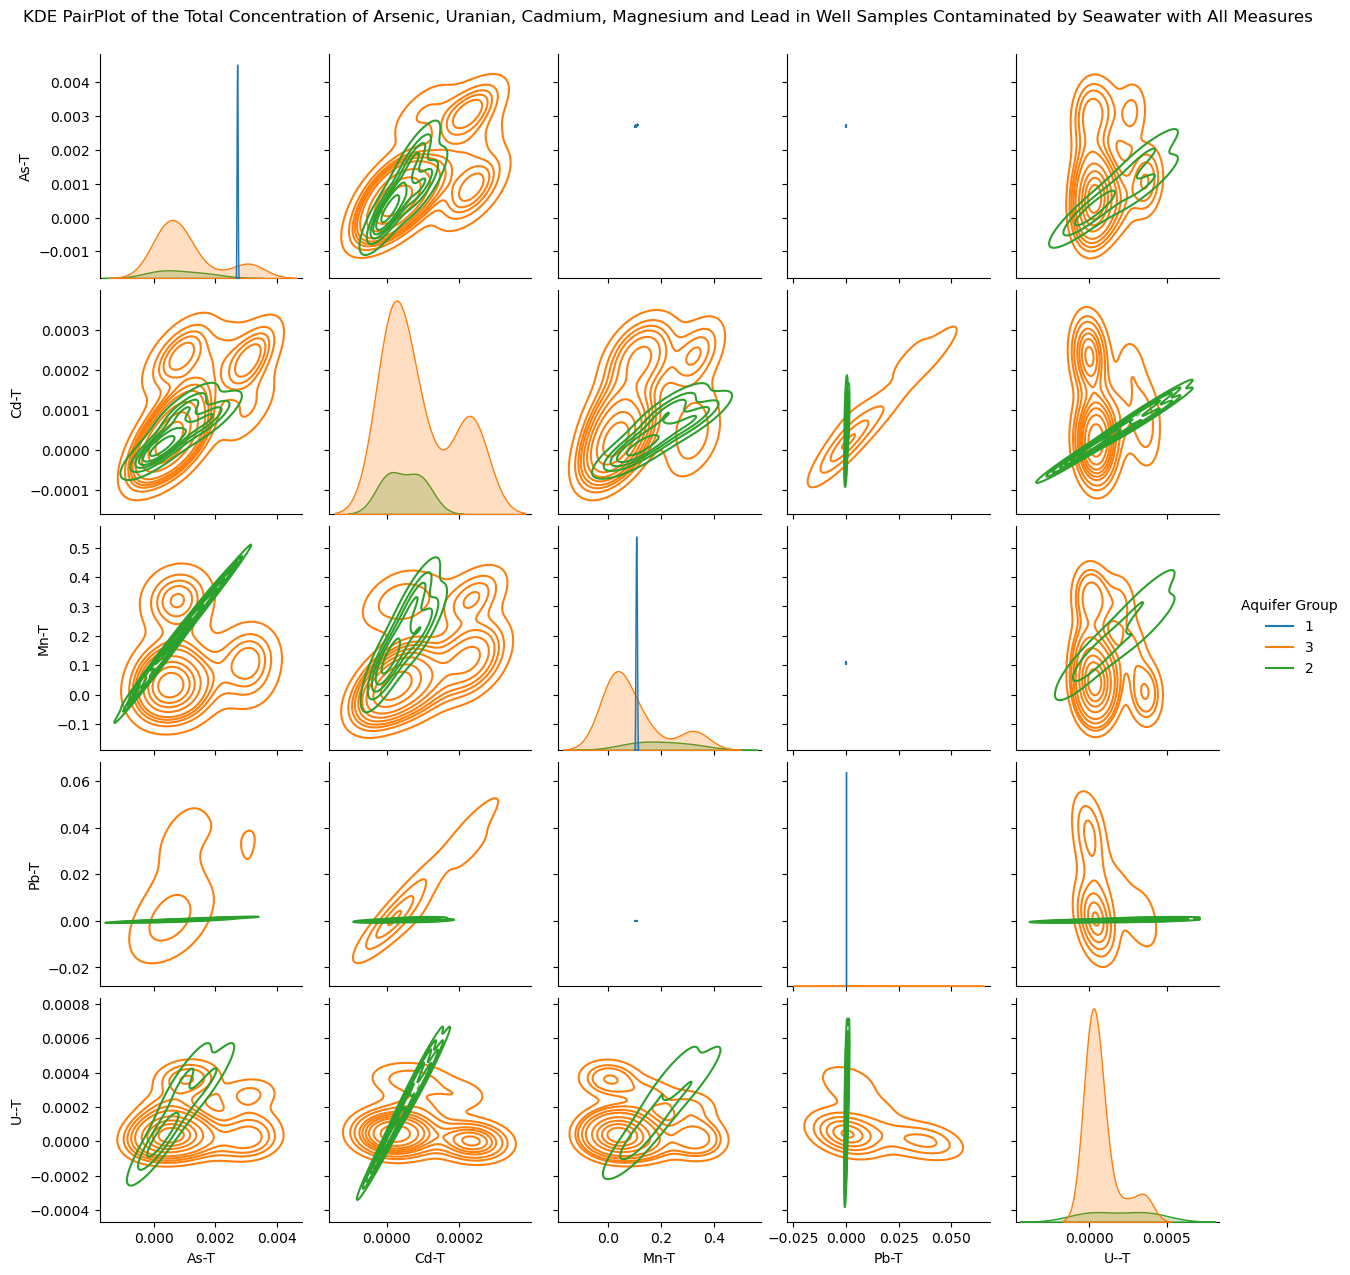

In [30]:
Metals_Total = DataAll[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group']]
Metalsg = sns.pairplot(Metals_Total, hue="Aquifer Group")
Metalsg.fig.suptitle("PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater with All Measures", y=1.02)
plt.savefig('Figures/pairplotmetalsSWIall.png') # Save the first figure

Metalsh = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="hist")
Metalsh.fig.suptitle("Histogram PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater with All Measures", y=1.02)
plt.savefig('Figures/histplotmetalsSWIall.png') 

Metalsf = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="kde")
Metalsf.fig.suptitle("KDE PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater with All Measures", y=1.02)
plt.savefig('Figures/KDEplotmetalsSWIall.png') 


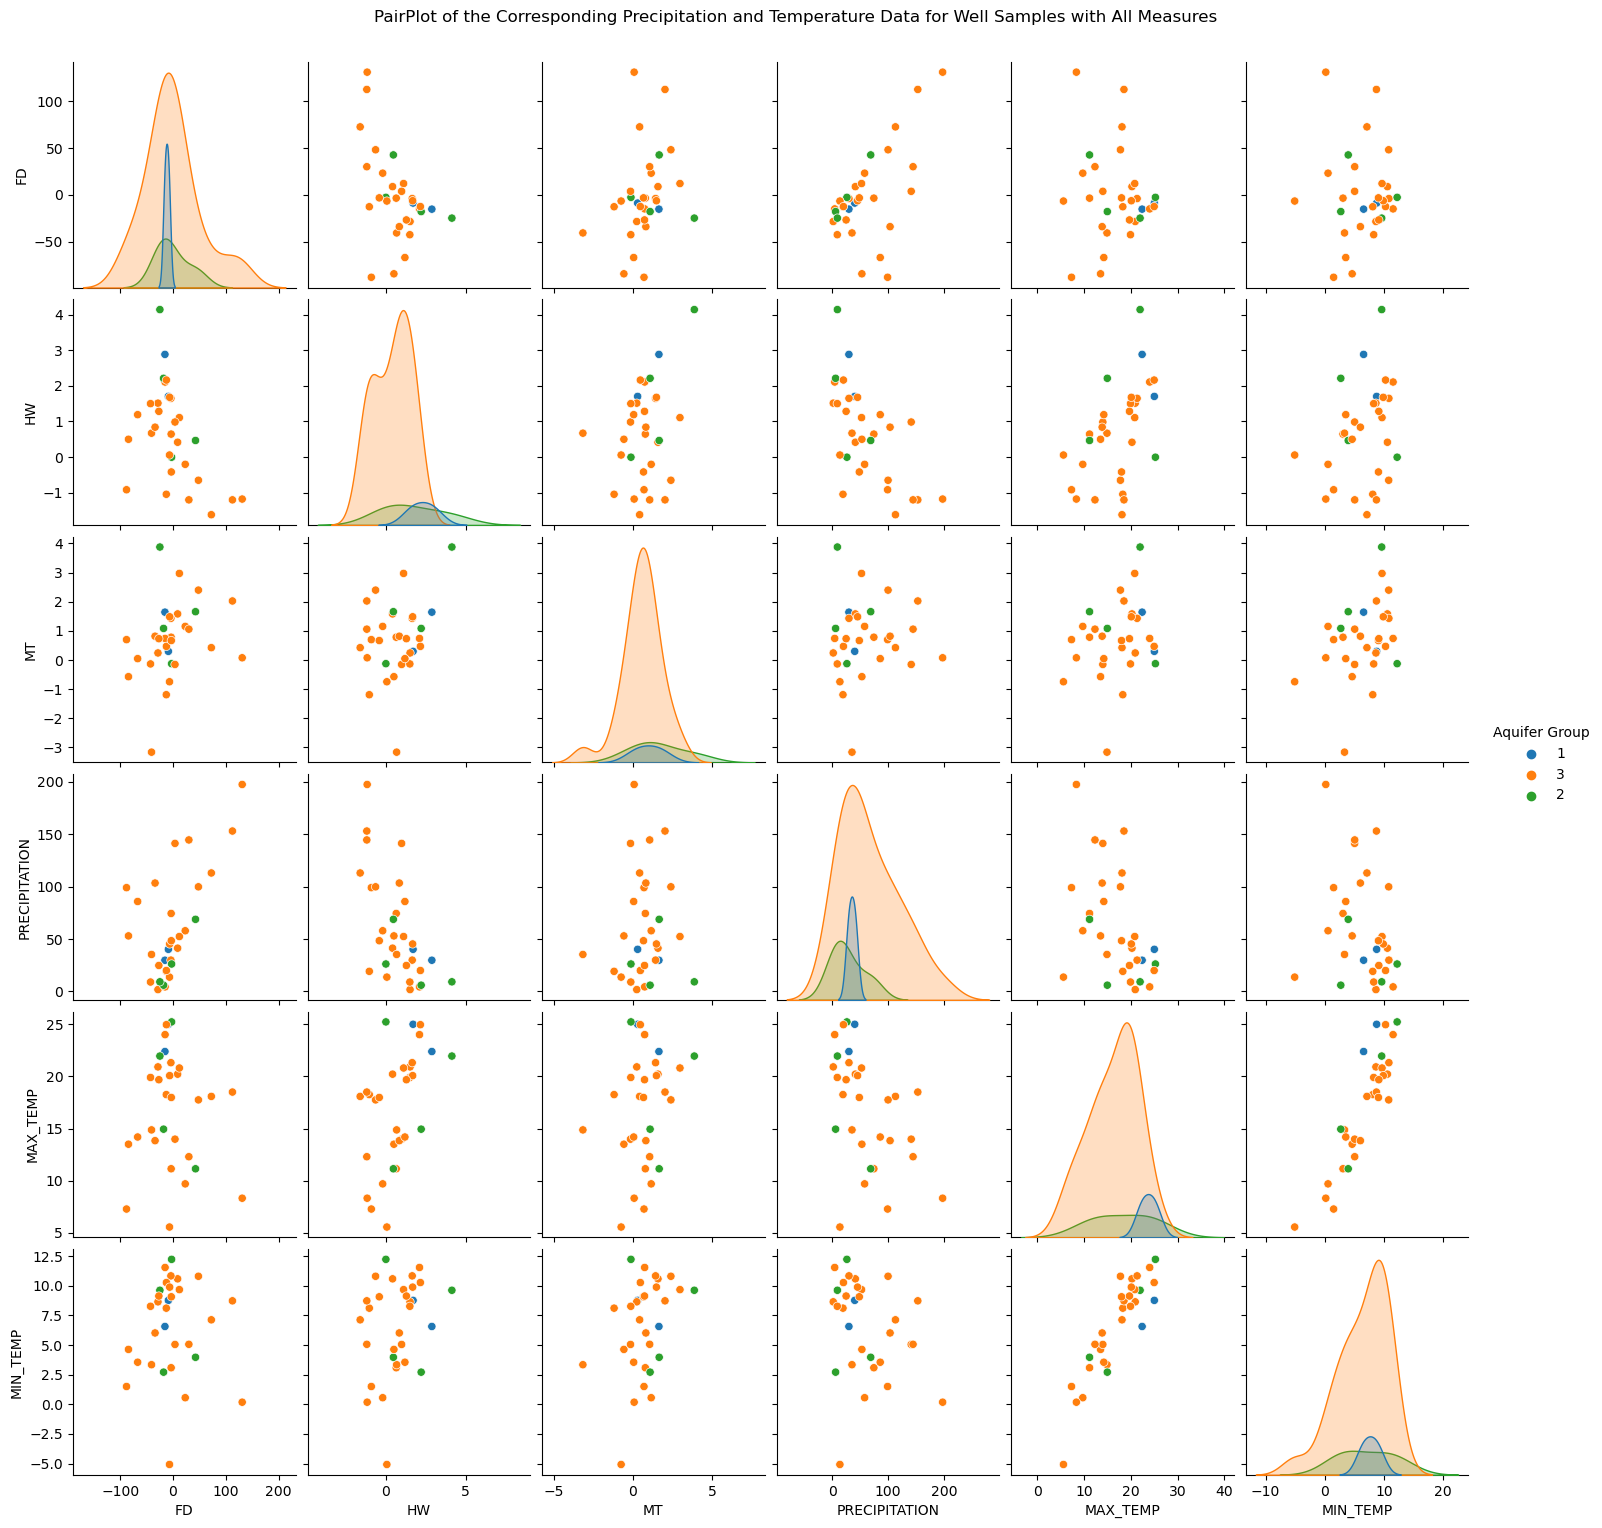

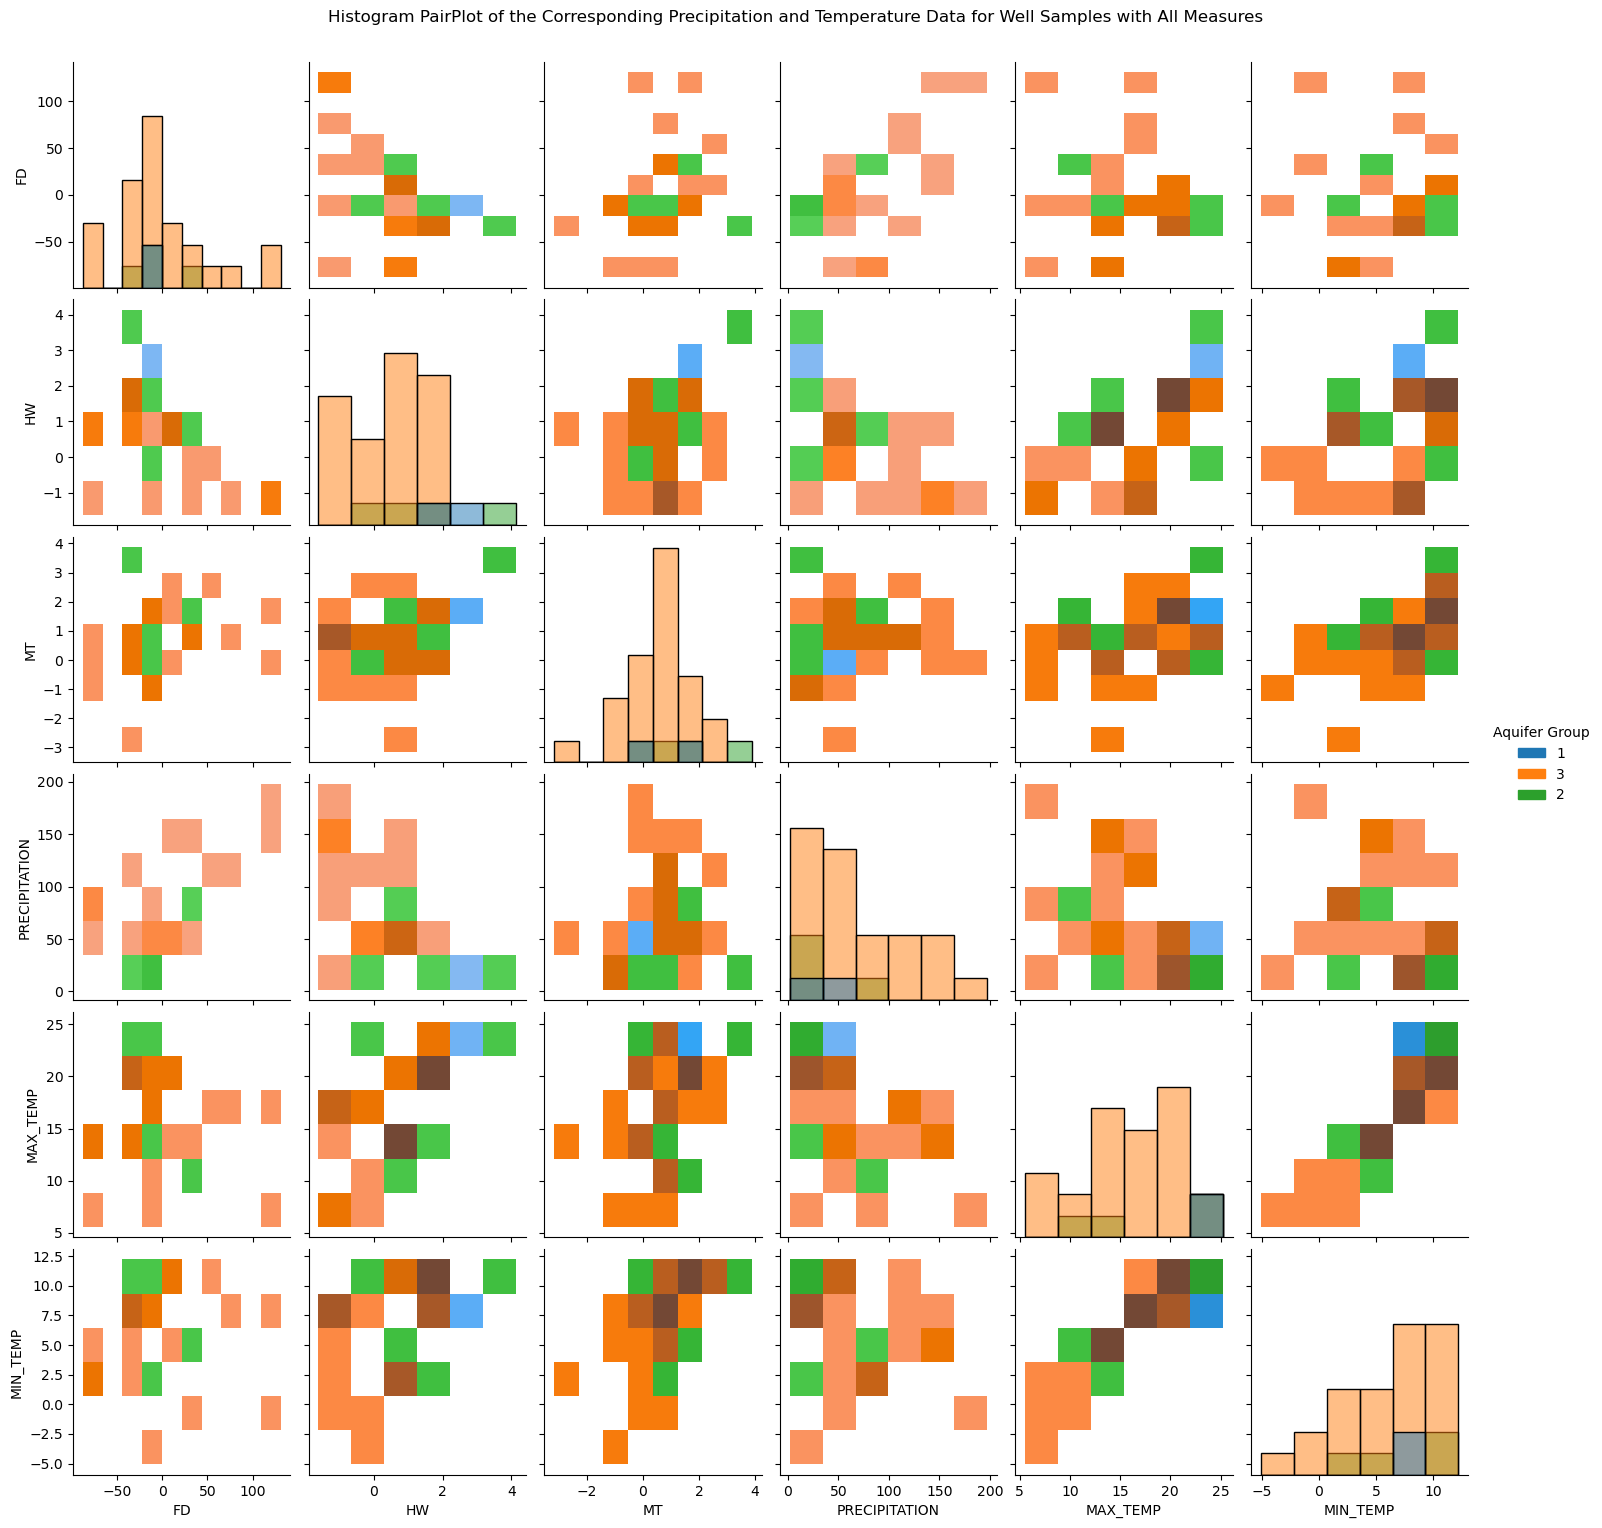

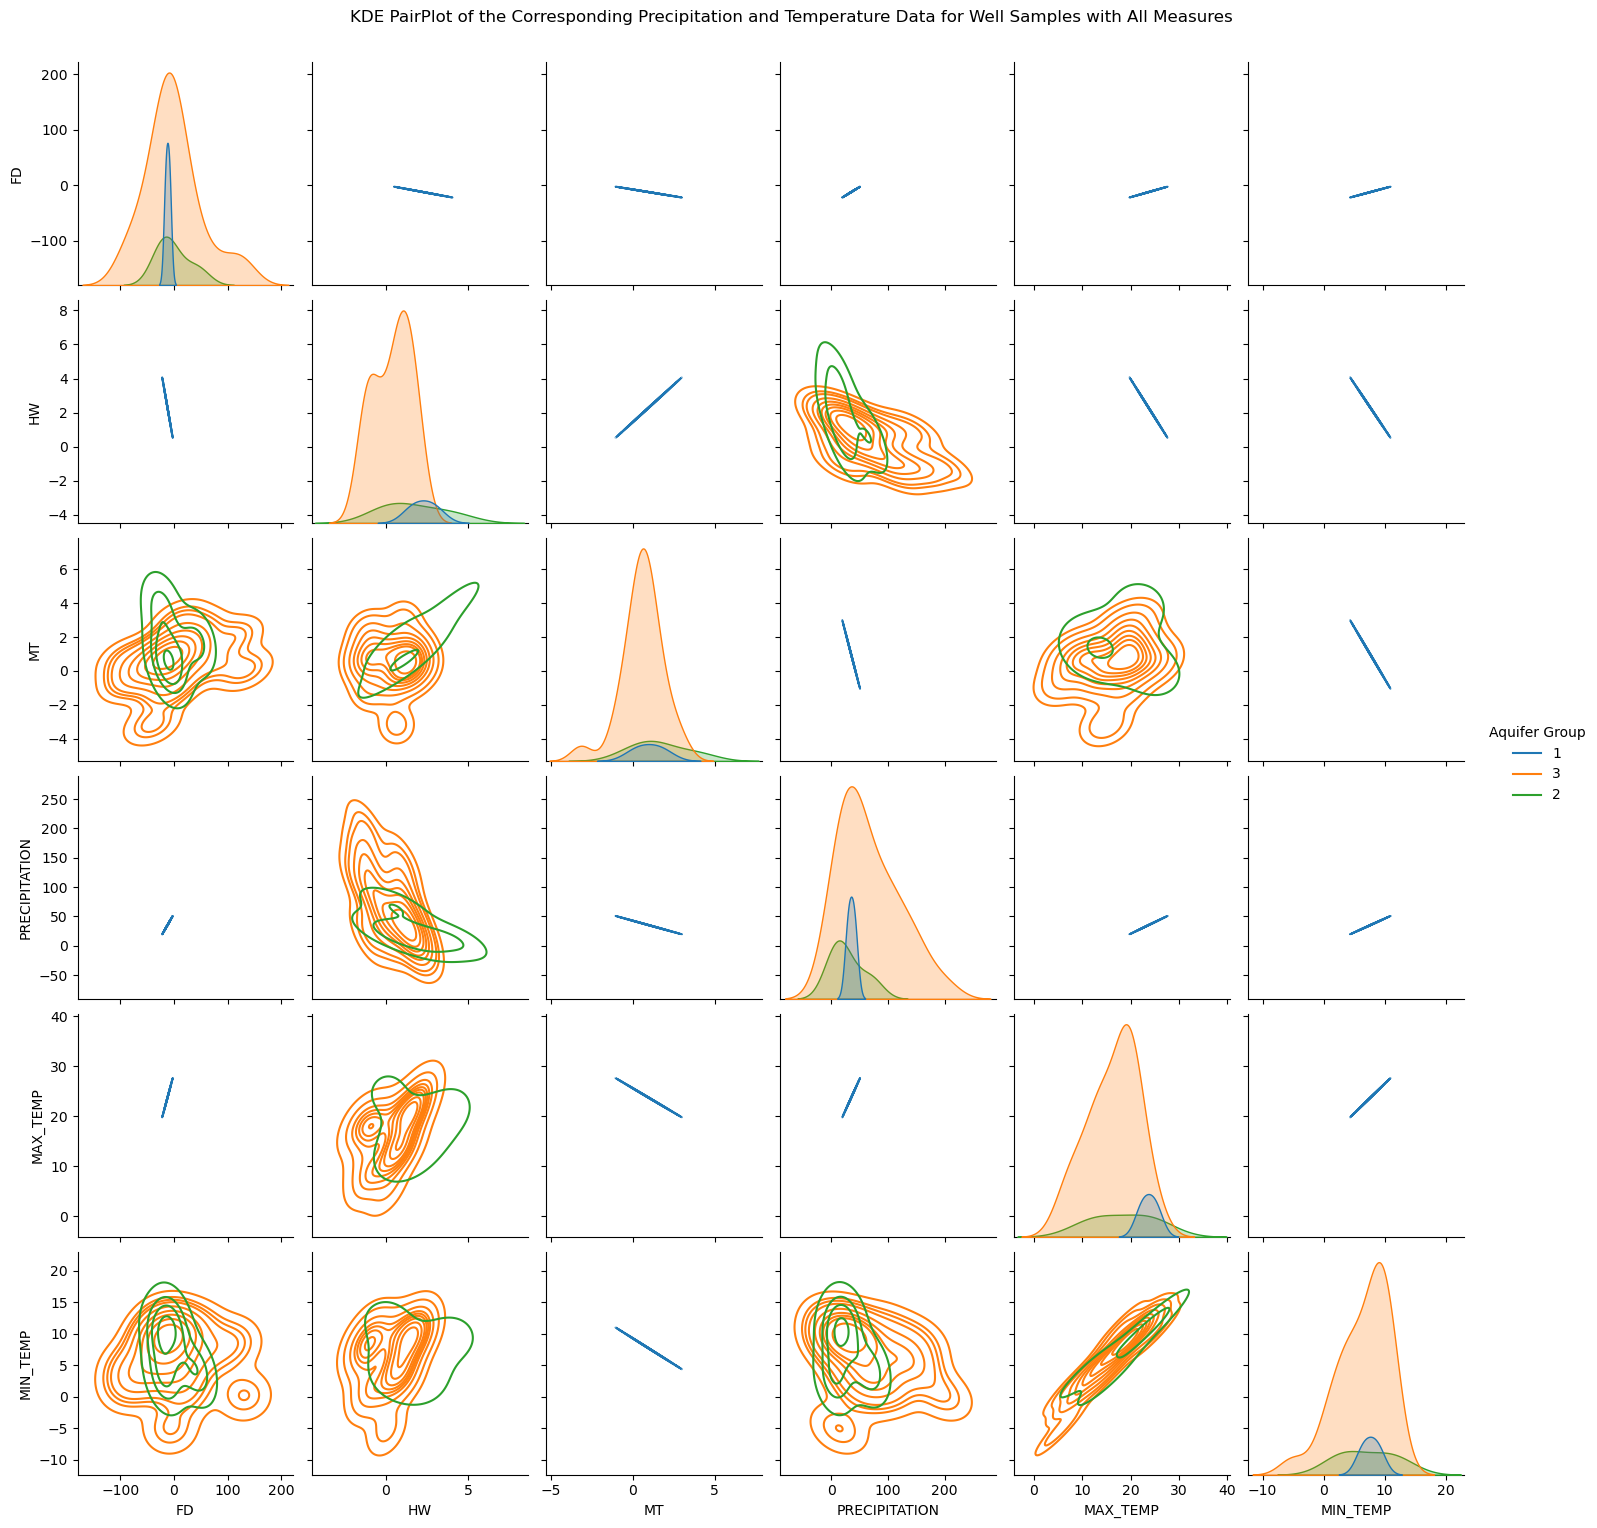

In [31]:
Precept = DataAll[['FD', 'HW', 'MT', 'Aquifer Group', 'PRECIPITATION', 'MAX_TEMP', 'MIN_TEMP']]
Preceptg= sns.pairplot(Precept, hue="Aquifer Group")
Preceptg.fig.suptitle("PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples with All Measures", y=1.02)
plt.savefig('Figures/pairplotPreceptSWIall.png') # Save the first figure

Precepth = sns.pairplot(Precept, hue="Aquifer Group", kind="hist")
Precepth.fig.suptitle("Histogram PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples with All Measures", y=1.02)
plt.savefig('Figures/histplotPreceptSWIall.png') 

Preceptf = sns.pairplot(Precept, hue="Aquifer Group", kind="kde")
Preceptf.fig.suptitle("KDE PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples with All Measures", y=1.02)
plt.savefig('Figures/KDEplotPreceptSWIall.png') 

In [32]:
OthersD = DataAll[['Alkalinity Total 4.5', 'Ca-T', 'Fe-T',
       'N.Kjel:T', 'P--T', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T', 'Aquifer Group']]

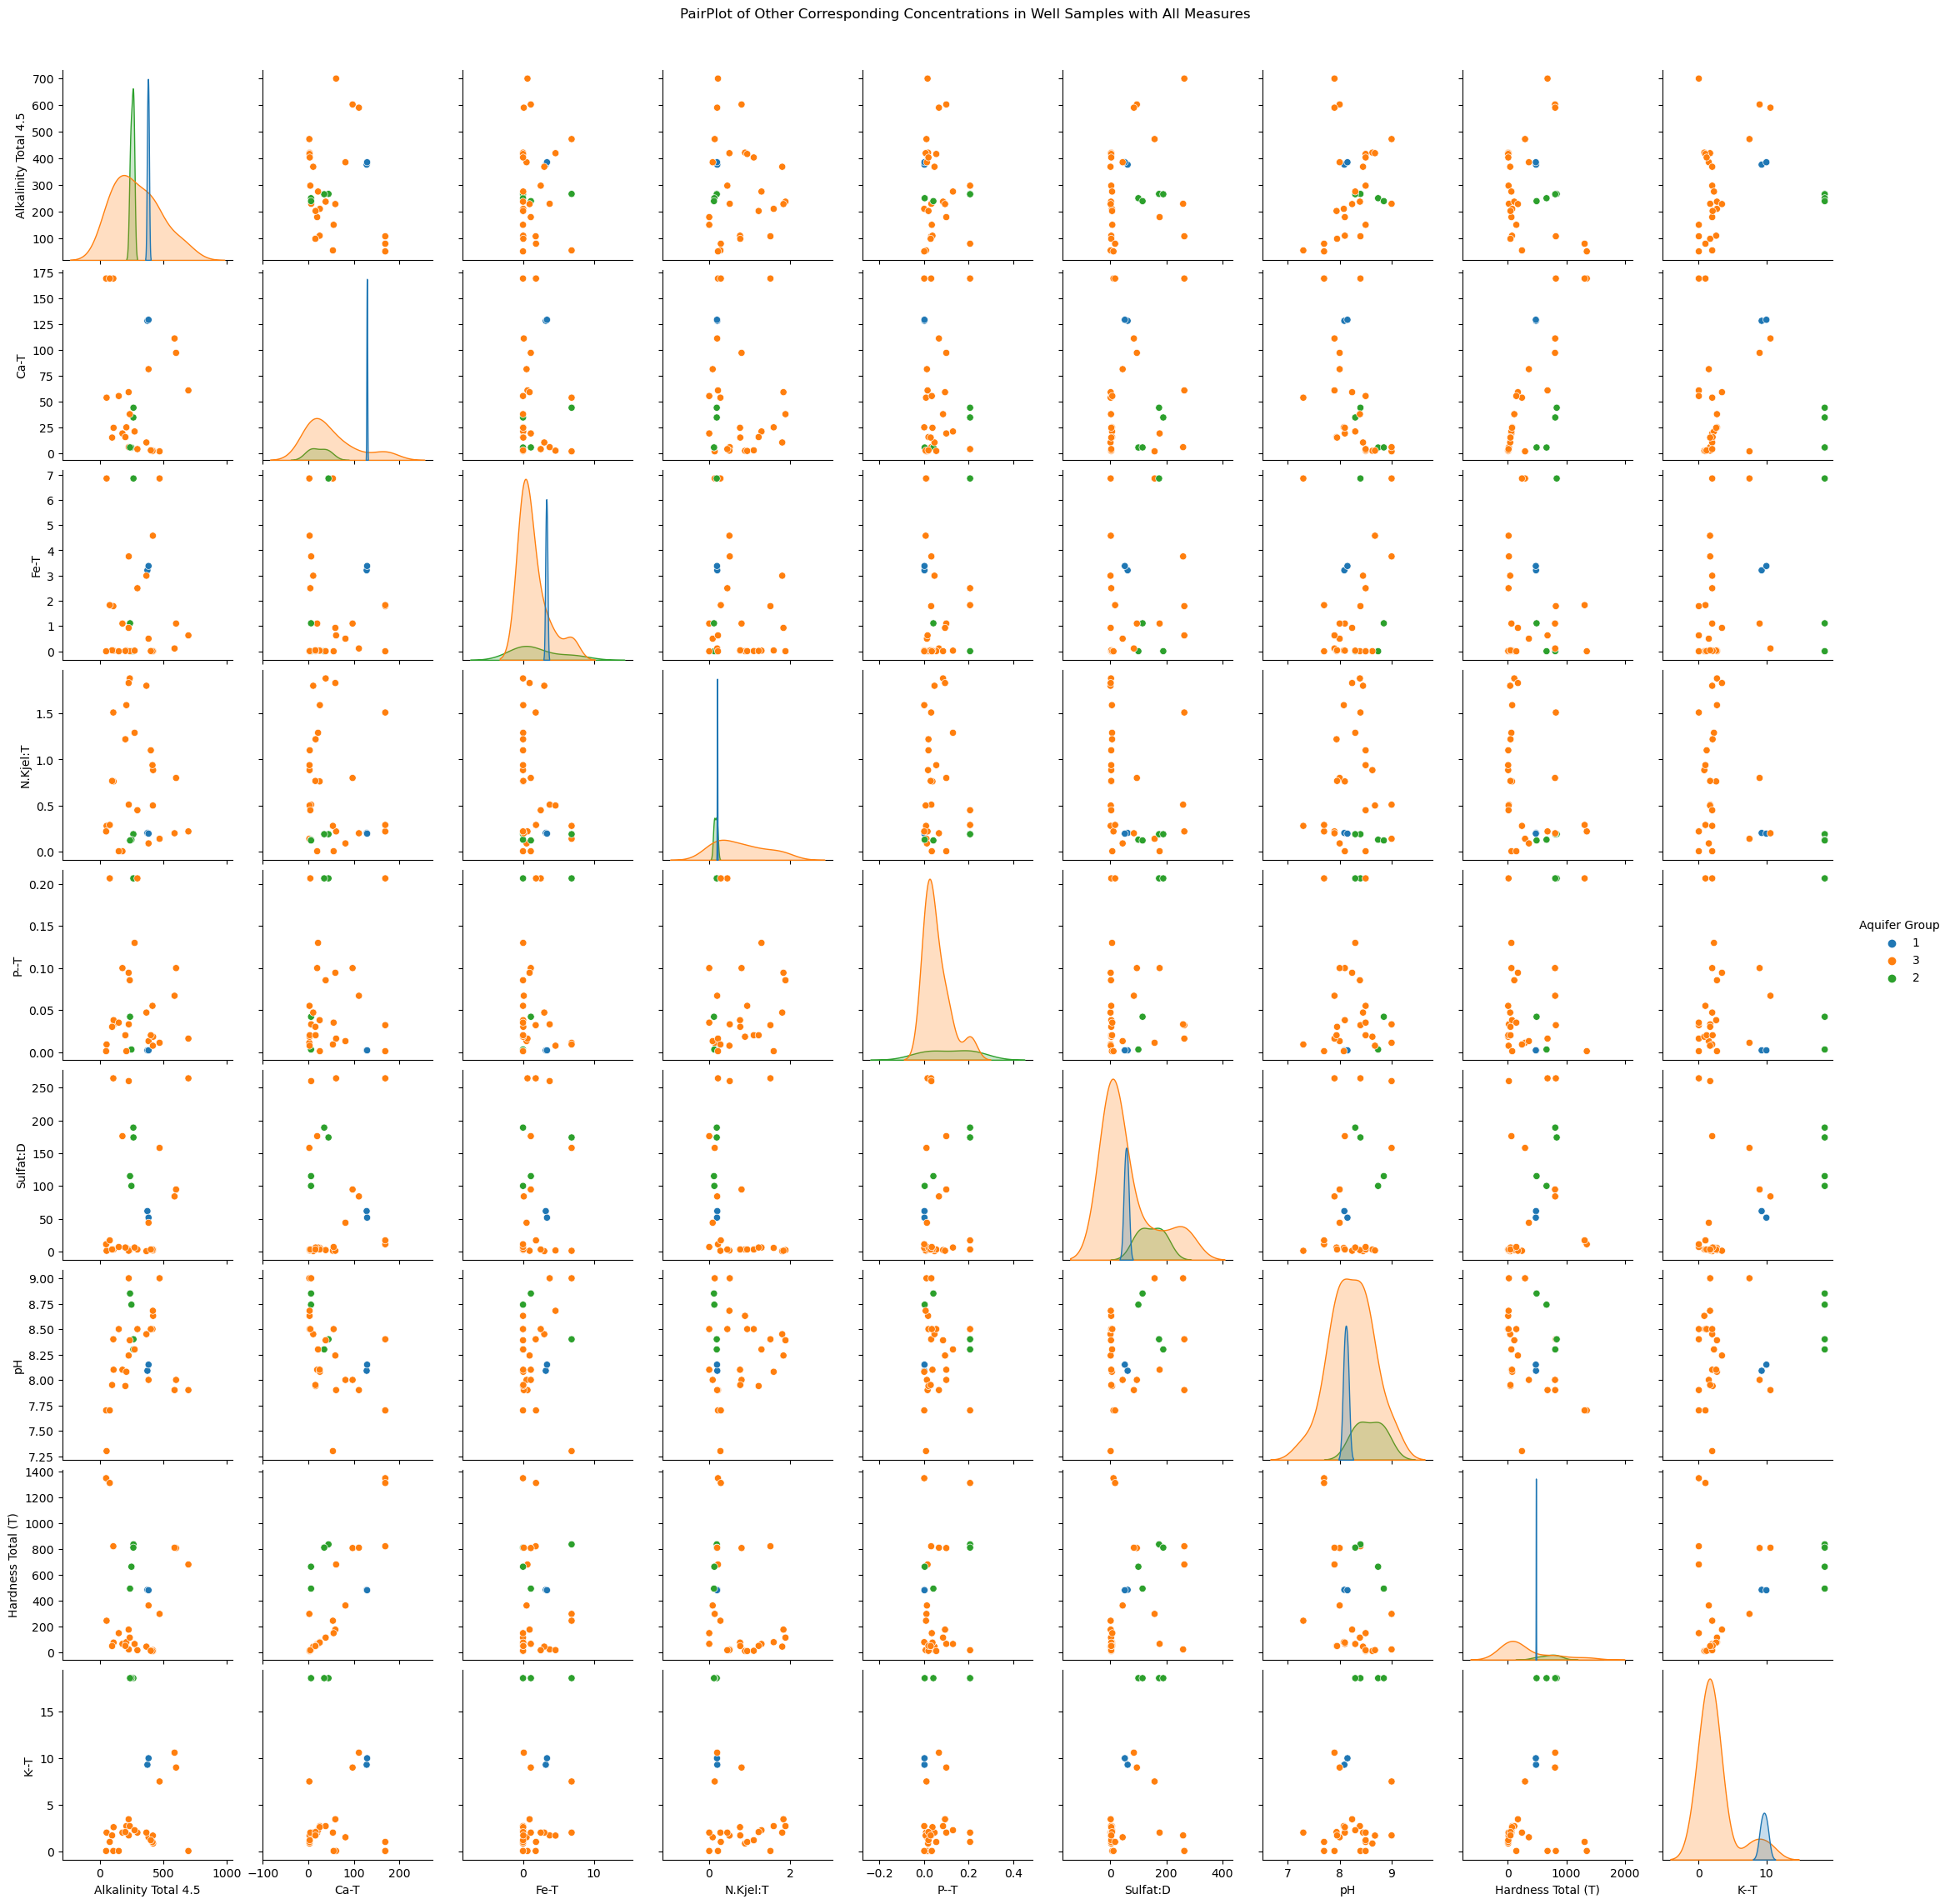

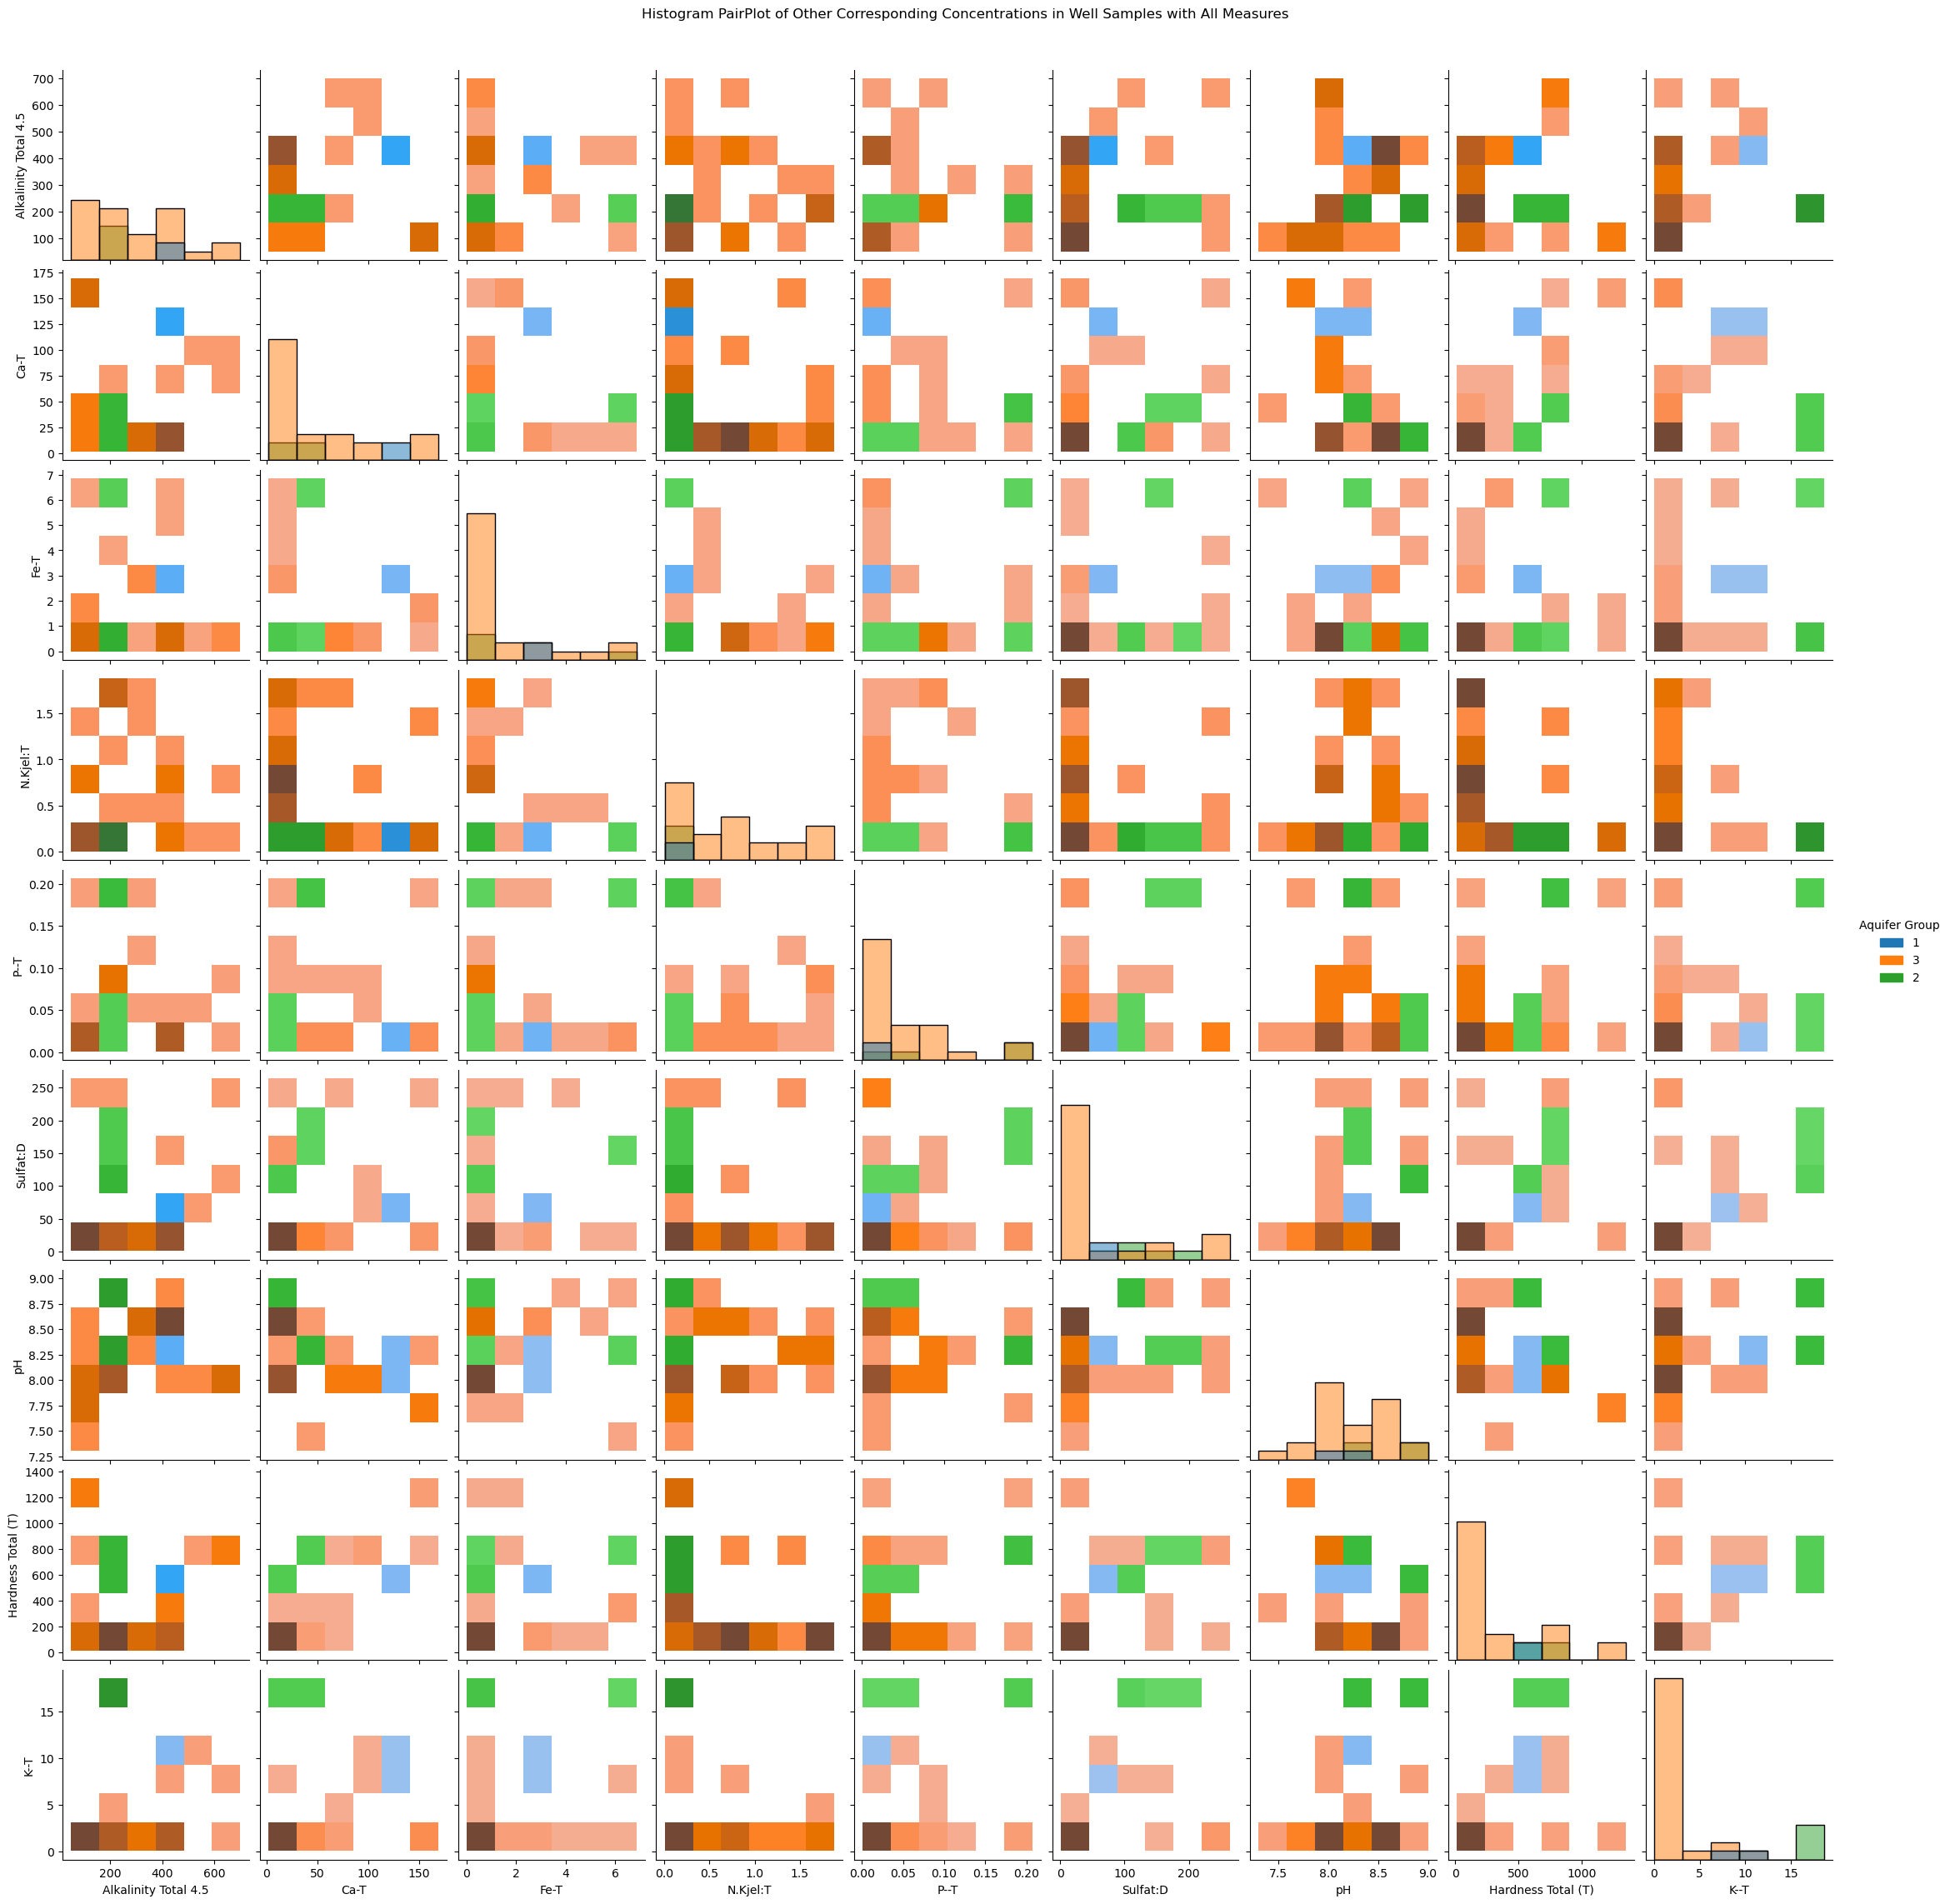

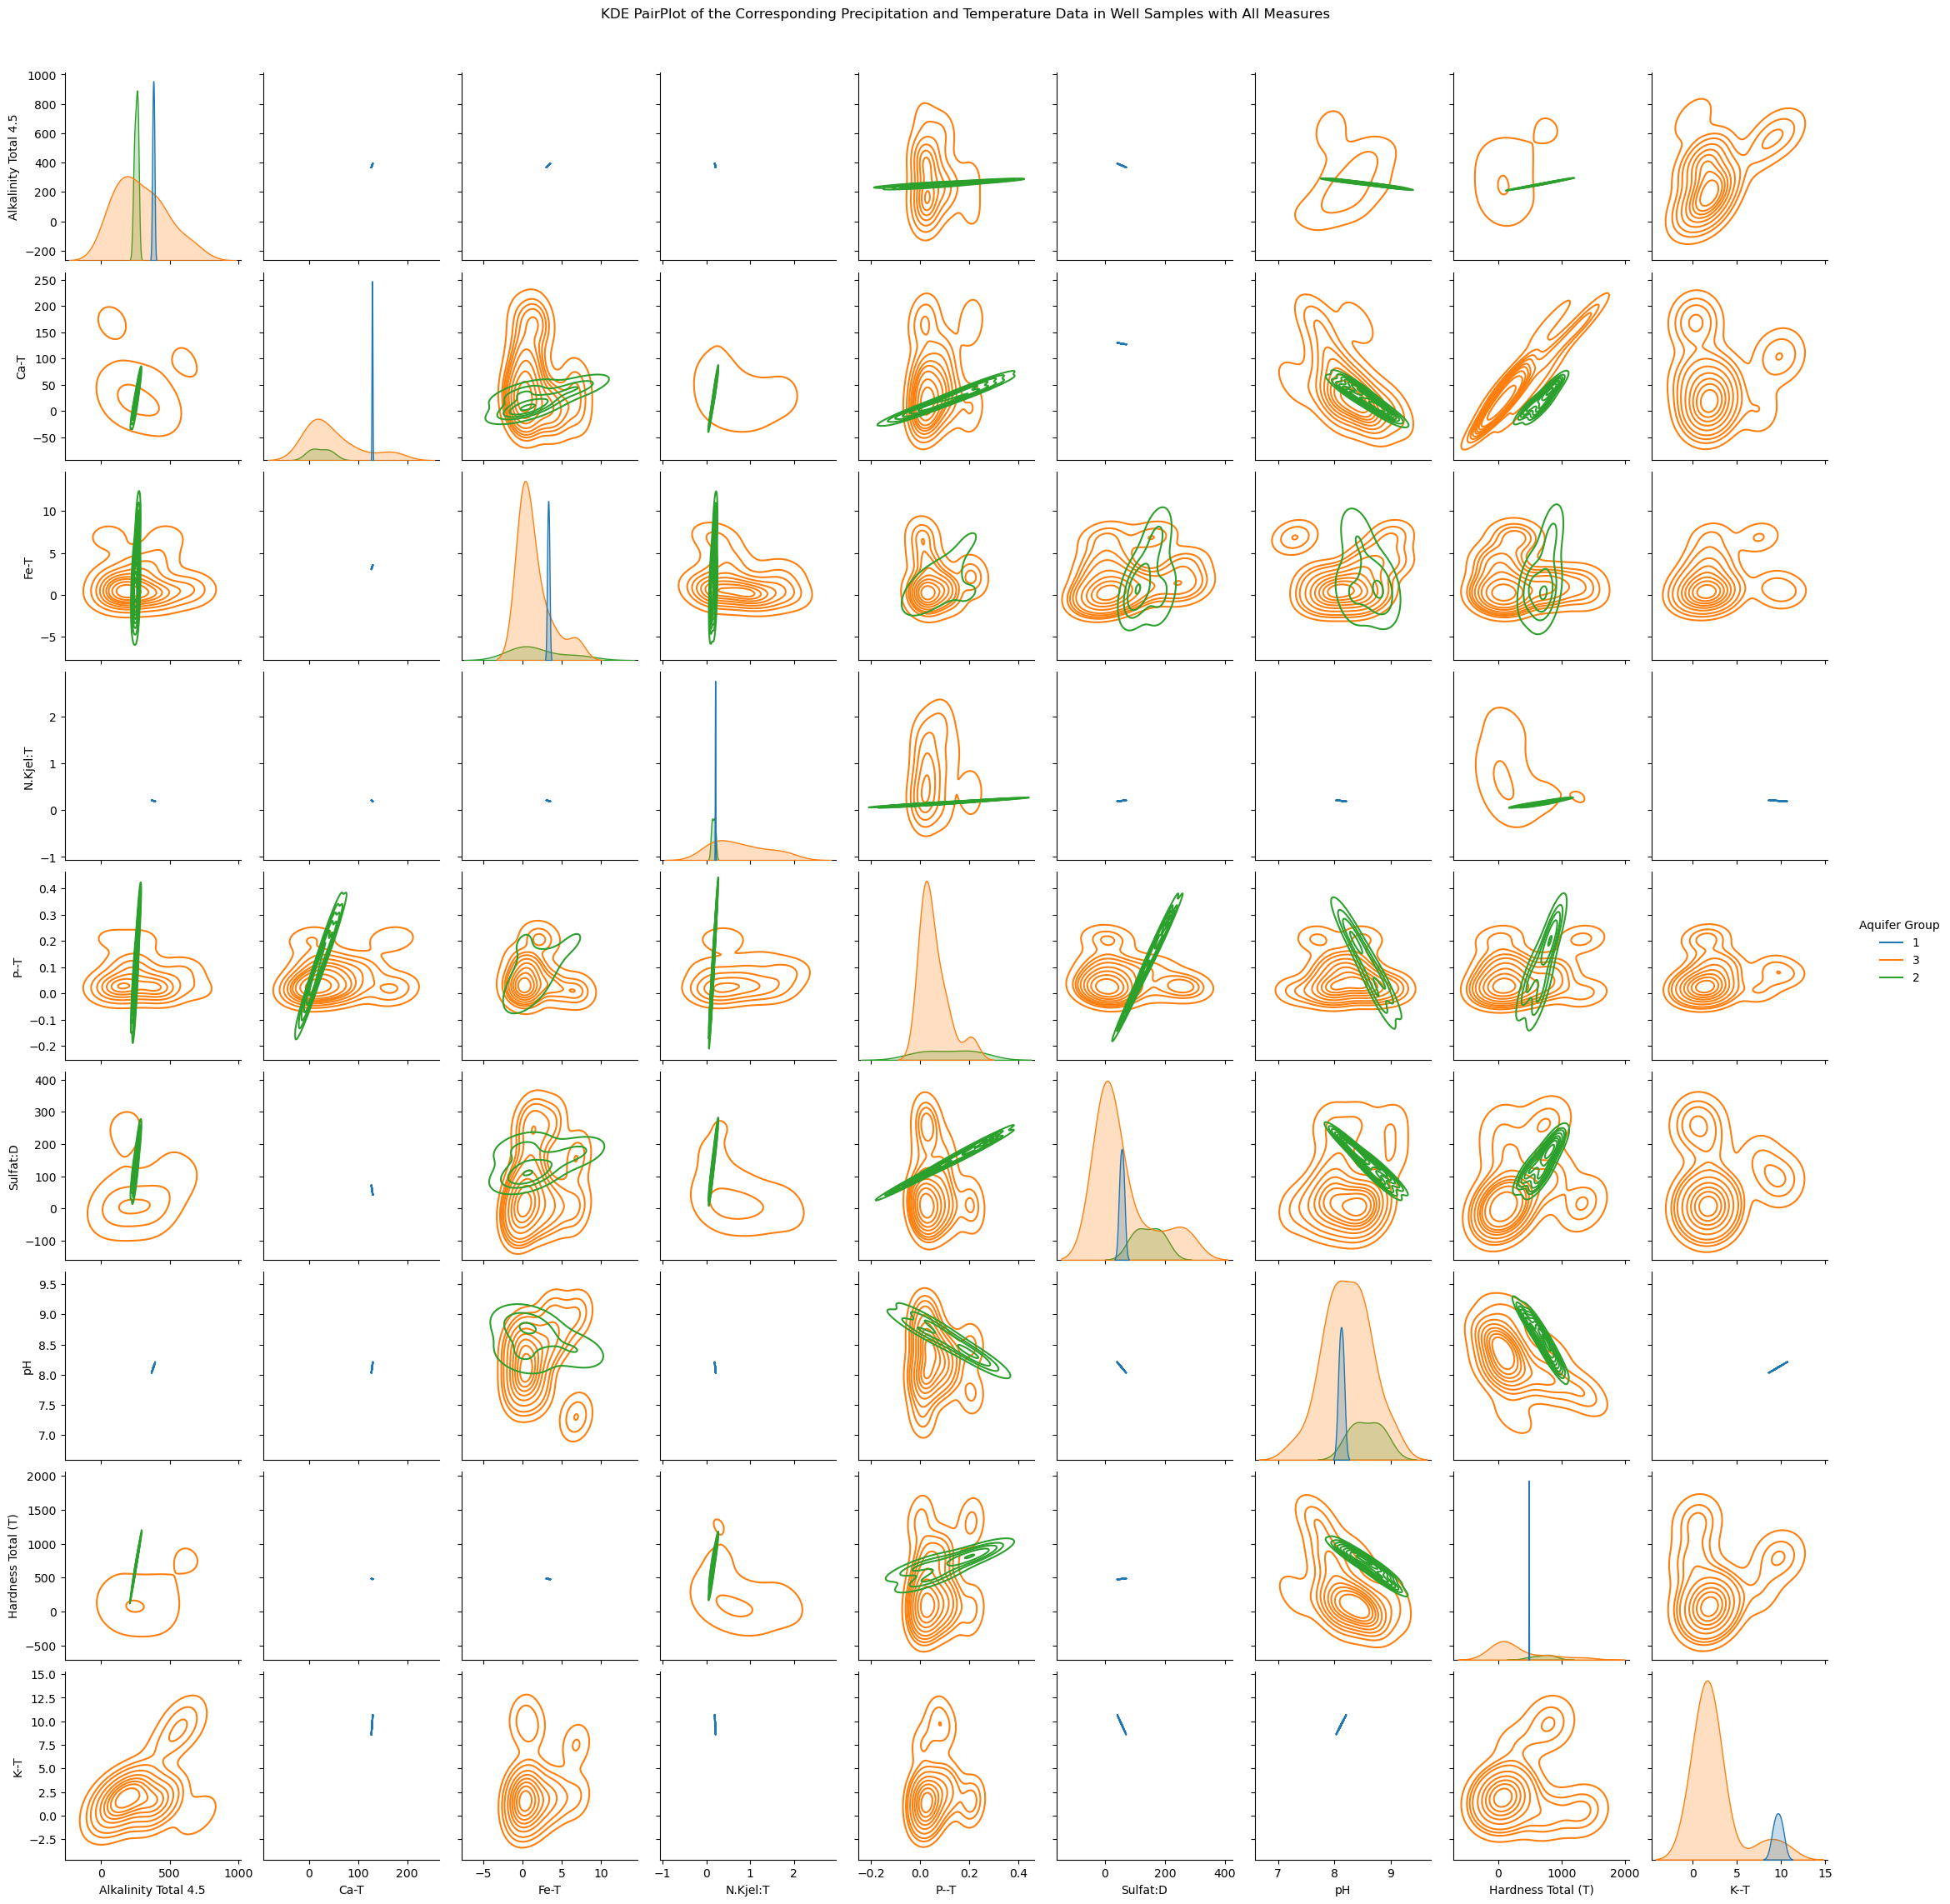

In [33]:
OthersDg= sns.pairplot(OthersD, hue="Aquifer Group")
OthersDg.fig.suptitle("PairPlot of Other Corresponding Concentrations in Well Samples with All Measures", y=1.02)
plt.savefig('Figures/pairplotOthersDSWIall.png') # Save the first figure

OthersDh = sns.pairplot(OthersD, hue="Aquifer Group", kind="hist")
OthersDh.fig.suptitle("Histogram PairPlot of Other Corresponding Concentrations in Well Samples with All Measures", y=1.02)
plt.savefig('Figures/histplotOthersDSWIall.png') 

Othersf = sns.pairplot(OthersD, hue="Aquifer Group", kind="kde")
Othersf.fig.suptitle("KDE PairPlot of the Corresponding Precipitation and Temperature Data in Well Samples with All Measures", y=1.02)
plt.savefig('Figures/KDEplotOthersSWIall.png') 

In [36]:
df_alltime = Datawithtime[(Datawithtime['Chlrid:D'] > 150) &(Datawithtime['Specific Conductance'] > 1000) & (Datawithtime['Residue Filterable 1.0u'] > 750)]
cleaned_dataset_array2 = replace_outliers_with_iqr(df_alltime[numeric_cols1], 1.5)
df_alltime[numeric_cols1] = cleaned_dataset_array2
#cleaned_dataset_array2a = replace_outliers_with_threshold(df_alltime[numeric_cols], threshold_multiplier=3)
#cleaned_dataset2 = pd.DataFrame(cleaned_dataset_array2a, columns=numeric_cols, index=df_alltime.index)
#df_alltime[numeric_cols] = cleaned_dataset2

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_33168\2659370452.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_alltime[numeric_cols1] = cleaned_dataset_array2


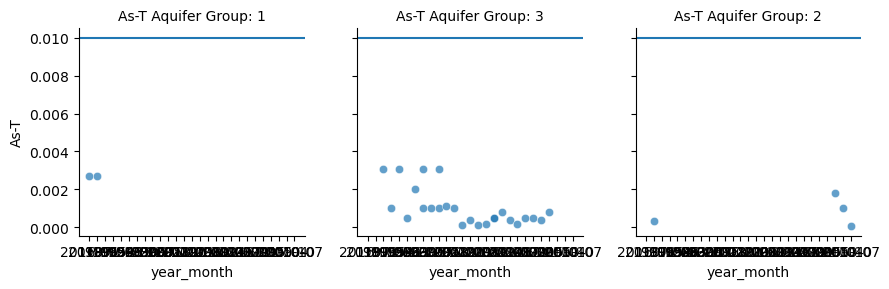

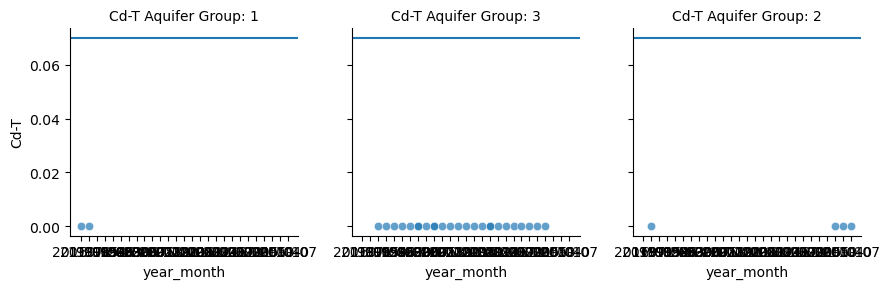

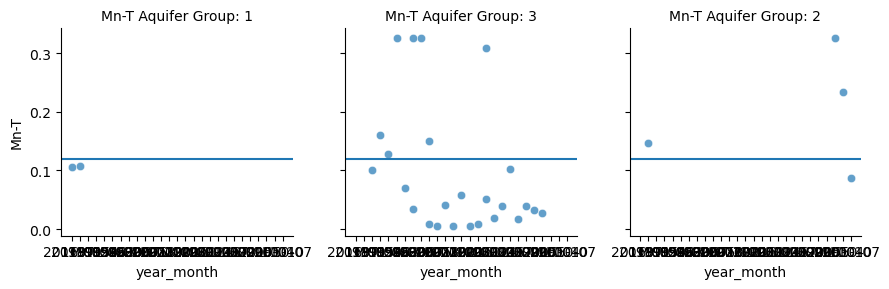

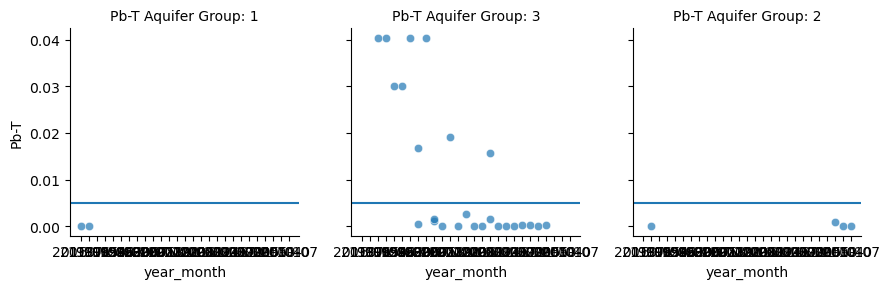

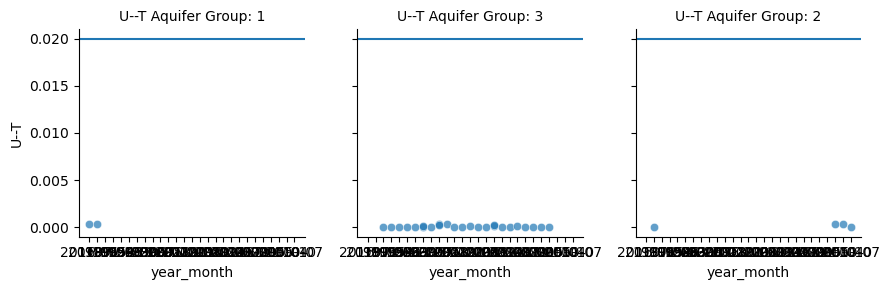

<Figure size 1000x800 with 0 Axes>

In [37]:
Total_Metals = df_alltime[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group', 'year_month']]

# Assuming Total_Metals DataFrame already exists
As = sns.FacetGrid(Total_Metals, col="Aquifer Group")
As.map(sns.scatterplot, "year_month", 'As-T', alpha=.7)
As.map(lambda x, **kwargs: plt.axhline(y=0.01, **kwargs), "year_month")
As.set_titles("As-T Aquifer Group: {col_name}")  # Setting title for each subplot

Cd = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Cd.map(sns.scatterplot, "year_month", 'Cd-T', alpha=.7)
Cd.map(lambda x, **kwargs: plt.axhline(y=0.07, **kwargs), "year_month")
Cd.set_titles("Cd-T Aquifer Group: {col_name}")  # Setting title for each subplot

Mn = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Mn.map(sns.scatterplot, "year_month", 'Mn-T', alpha=.7)
Mn.map(lambda x, **kwargs: plt.axhline(y=0.12, **kwargs), "year_month")
Mn.set_titles("Mn-T Aquifer Group: {col_name}")  # Setting title for each subplot

Pb = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Pb.map(sns.scatterplot, "year_month", 'Pb-T', alpha=.7)
Pb.map(lambda x, **kwargs: plt.axhline(y=0.005, **kwargs), "year_month")
Pb.set_titles("Pb-T Aquifer Group: {col_name}")  # Setting title for each subplot

UT = sns.FacetGrid(Total_Metals, col="Aquifer Group")
UT.map(sns.scatterplot, "year_month", 'U--T', alpha=.7)
UT.map(lambda x, **kwargs: plt.axhline(y=0.02, **kwargs), "year_month")
UT.set_titles("U--T Aquifer Group: {col_name}")  # Setting title for each subplot

#plt.suptitle("Well Water Samples with As, Mn, Pb and U Concentrations over Canadian Drinking Water Standards", fontsize=12, y=1.02)
plt.tight_layout()  # This line is to prevent overlapping of the title and the top plot
plt.show()
plt.savefig('Figures/metalsoverCADdrinkingwaterSWIall.png')

In [38]:
CANDMetalspre = df_alltime[['OBSWELL', 'As-T', 'Mn-T', 'Pb-T', 'U--T']]
filtered_dfAs = CANDMetalspre[(CANDMetalspre['As-T'] >= 0.01)]
obs_well_valuesAs = filtered_dfAs['OBSWELL']
obs_well_valuesAs.shape

(0,)

In [39]:
filtered_dfMn = df_alltime[(CANDMetalspre['Mn-T'] >= 0.12)]
obs_well_valuesMn = filtered_dfMn['OBSWELL']
obs_well_valuesMn.shape

(10,)

In [40]:
filtered_dfPb = df_alltime[(CANDMetalspre['Pb-T'] >= 0.005)]
obs_well_valuesPb = filtered_dfPb['OBSWELL']
obs_well_valuesPb.shape

(9,)

In [41]:
filtered_dfU = df_alltime[(CANDMetalspre['U--T'] >= 0.02)]
obs_well_valuesU = filtered_dfU['OBSWELL']
obs_well_valuesU.shape

(0,)

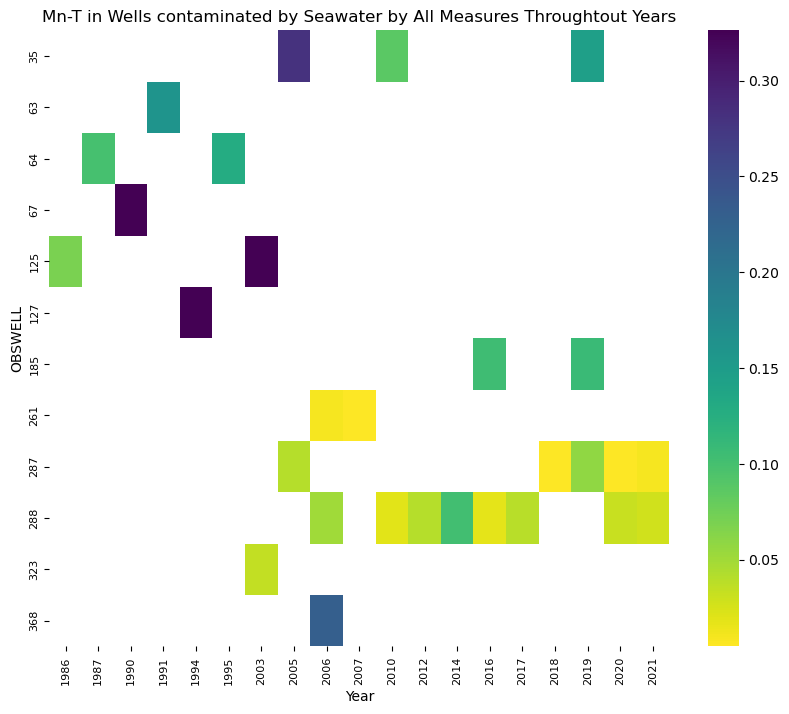

<Figure size 1000x800 with 0 Axes>

In [42]:
df_alltime = df_alltime.copy()  # create a copy of Datawithtime to avoid modifying the original DataFrame
df_alltime['DATE'] = pd.to_datetime(df_alltime['DATE'])  # convert 'DATE' column to datetime
df_alltime['Year'] = df_alltime['DATE'].dt.year  # extract year from 'DATE' column

SWIall = df_alltime.pivot_table(index="OBSWELL", columns="Year", values="Mn-T")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWIall, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Mn-T in Wells contaminated by Seawater by All Measures Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapAllMN.png') 

In [44]:
DataClSCtime = Datawithtime[(Datawithtime['Chlrid:D'] > 150) &(Datawithtime['Specific Conductance'] > 1000)]
cleaned_dataset_array2b = replace_outliers_with_iqr(DataClSCtime[numeric_cols1], 1.5)
DataClSCtime[numeric_cols1] = cleaned_dataset_array2b
'''
cleaned_dataset_array2c = replace_outliers_with_threshold(DataClSCtime[numeric_cols], threshold_multiplier=3)
cleaned_dataset2a = pd.DataFrame(cleaned_dataset_array2c, columns=numeric_cols, index=DataClSCtime.index)
DataClSCtime[numeric_cols] = cleaned_dataset2a
'''

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_33168\3121386836.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DataClSCtime[numeric_cols1] = cleaned_dataset_array2b


'\ncleaned_dataset_array2c = replace_outliers_with_threshold(DataClSCtime[numeric_cols], threshold_multiplier=3)\ncleaned_dataset2a = pd.DataFrame(cleaned_dataset_array2c, columns=numeric_cols, index=DataClSCtime.index)\nDataClSCtime[numeric_cols] = cleaned_dataset2a\n'

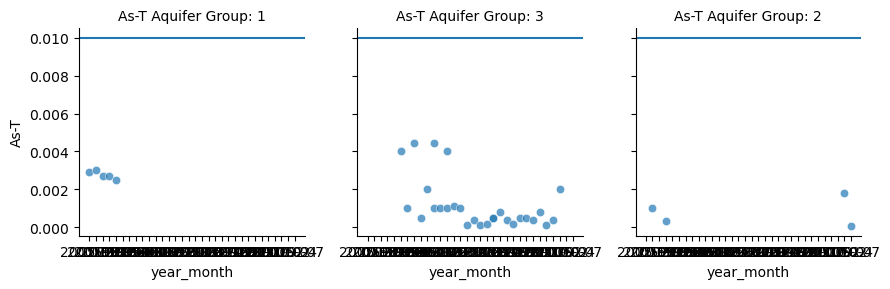

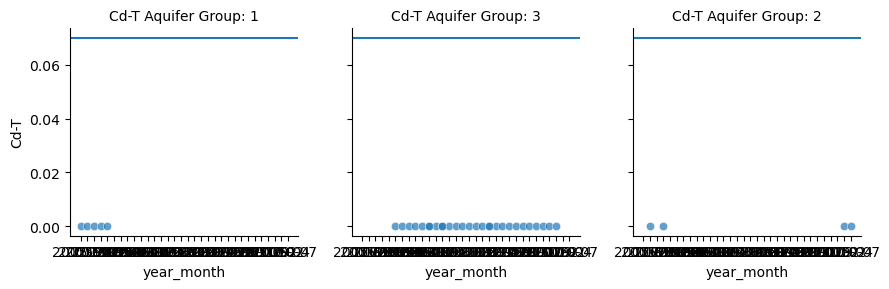

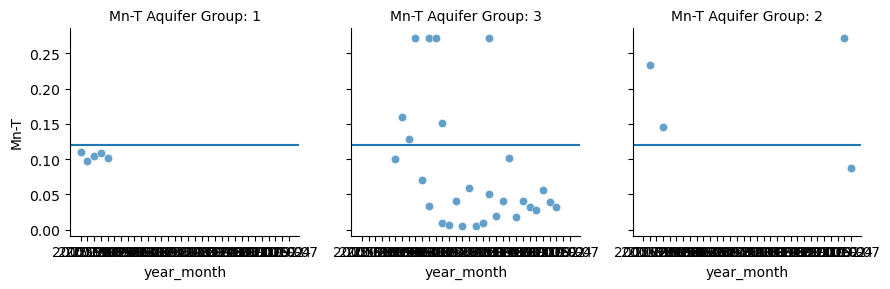

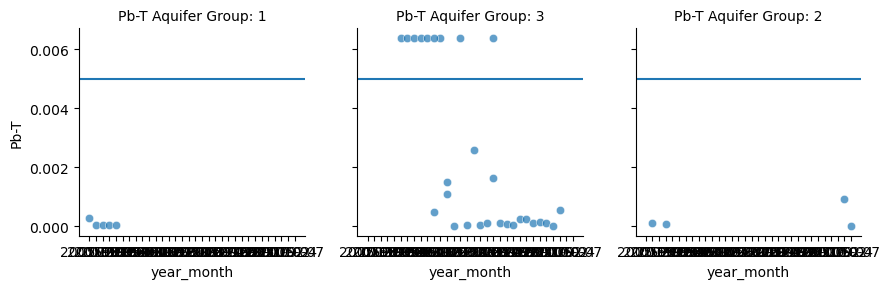

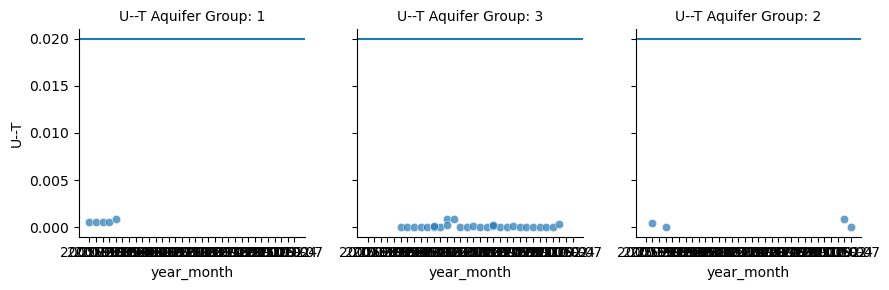

<Figure size 1000x800 with 0 Axes>

In [45]:
Total_Metals = DataClSCtime[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group', 'year_month']]

# Assuming Total_Metals DataFrame already exists
As = sns.FacetGrid(Total_Metals, col="Aquifer Group")
As.map(sns.scatterplot, "year_month", 'As-T', alpha=.7)
As.map(lambda x, **kwargs: plt.axhline(y=0.01, **kwargs), "year_month")
As.set_titles("As-T Aquifer Group: {col_name}")  # Setting title for each subplot

Cd = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Cd.map(sns.scatterplot, "year_month", 'Cd-T', alpha=.7)
Cd.map(lambda x, **kwargs: plt.axhline(y=0.07, **kwargs), "year_month")
Cd.set_titles("Cd-T Aquifer Group: {col_name}")  # Setting title for each subplot

Mn = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Mn.map(sns.scatterplot, "year_month", 'Mn-T', alpha=.7)
Mn.map(lambda x, **kwargs: plt.axhline(y=0.12, **kwargs), "year_month")
Mn.set_titles("Mn-T Aquifer Group: {col_name}")  # Setting title for each subplot

Pb = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Pb.map(sns.scatterplot, "year_month", 'Pb-T', alpha=.7)
Pb.map(lambda x, **kwargs: plt.axhline(y=0.005, **kwargs), "year_month")
Pb.set_titles("Pb-T Aquifer Group: {col_name}")  # Setting title for each subplot

UT = sns.FacetGrid(Total_Metals, col="Aquifer Group")
UT.map(sns.scatterplot, "year_month", 'U--T', alpha=.7)
UT.map(lambda x, **kwargs: plt.axhline(y=0.02, **kwargs), "year_month")
UT.set_titles("U--T Aquifer Group: {col_name}")  # Setting title for each subplot

#plt.suptitle("Well Water Samples with As, Mn, Pb and U Concentrations over Canadian Drinking Water Standards", fontsize=12, y=1.02)
plt.tight_layout()  # This line is to prevent overlapping of the title and the top plot
plt.show()
plt.savefig('Figures/metalsoverCADdrinkingwaterSWIClSC.png')

In [46]:
CANDMetalspre = DataClSCtime[['OBSWELL', 'As-T', 'Mn-T', 'Pb-T', 'U--T']]
filtered_dfAs = CANDMetalspre[(CANDMetalspre['As-T'] >= 0.01)]
obs_well_valuesAs = filtered_dfAs['OBSWELL']
obs_well_valuesAs.shape

(0,)

In [47]:
filtered_dfMn = DataClSCtime[(CANDMetalspre['Mn-T'] >= 0.12)]
obs_well_valuesMn = filtered_dfMn['OBSWELL']
obs_well_valuesMn.shape

(10,)

In [48]:
filtered_dfPb = DataClSCtime[(CANDMetalspre['Pb-T'] >= 0.005)]
obs_well_valuesPb = filtered_dfPb['OBSWELL']
obs_well_valuesPb.shape

(9,)

In [49]:
filtered_dfU = DataClSCtime[(CANDMetalspre['U--T'] >= 0.02)]
obs_well_valuesU = filtered_dfU['OBSWELL']
obs_well_valuesU.shape

(0,)